# County-Level Maize (Corn) Grain Yield Prediction Using Agricultural, Climate and Soil Data

**Project Title:** County-Level Maize (Corn) Grain Yield Prediction Using Agricultural, Climate and Soil Data  
**Target Variable:** `corn_yield_bu_acre` (bushels per acre)  
**Problem Type:** Supervised Learning — Regression  
**Study Coverage:** 9 US Corn Belt states (`IA`, `IL`, `IN`, `MN`, `MO`, `NE`, `OH`, `SD`, `WI`), `2002–2025`  
**GitHub Repository:** https://github.com/ayankhan96686-create/ml-pbl

---

## 1. Project Introduction

Maize yield prediction estimates how many bushels of corn grain a county produces per acre (`corn_yield_bu_acre`). Predicting crop yield helps grain storage facilities plan capacity, helps agricultural agencies spot drought risk early, and shows how heat, rainfall, and soil conditions relate to harvest outcomes.

This project uses real multi-source data across nine Midwestern Corn Belt states:
- **USDA NASS Corn Yield:** Official county-level maize grain yield (target variable).
- **NOAA ClimDiv:** County-level monthly temperature and precipitation across the growing season.
- **PRISM Climate:** Gridded climate summaries extracted at county centroids (`2002–2025` annual summaries and `2026` provisional monthly values).
- **ISRIC SoilGrids:** Static county soil properties (clay, sand, silt, soil organic carbon, pH, bulk density).
- **USDA RMA Crop Insurance:** County-year planted acres, policies sold, liability, premiums, and subsidies.
- **USDA NASS Crop Condition & Progress:** State-level weekly crop health ratings and growth-stage progress aggregated by year.
- **USDA NASS Fertilizer Surveys:** State-level nutrient application rates for selected survey years.

*Note on unavailable sources:* Earlier project planning folders for `ERA5-Land`, `MODIS`, `Landsat`, `Sentinel-2`, and `gSSURGO` contained only README instructions without actual data files, so only the real available datasets listed above are used here.

## 2. Import Libraries

If you run this notebook in a fresh environment (such as Google Colab), install the required packages first using:
```bash
pip install -r https://raw.githubusercontent.com/ayankhan96686-create/ml-pbl/main/requirements.txt
```
Below is our single import cell with all libraries needed for data loading, cleaning, EDA, statistical tests, and Machine Learning.

In [1]:
from pathlib import Path
import time

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
import statsmodels.api as sm

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    RandomForestClassifier,
)

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    confusion_matrix,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.feature_selection import f_regression

# Optional gradient boosting package
try:
    import xgboost as xgb
except ImportError:
    xgb = None
    print("XGBoost is not installed. Optional install: pip install xgboost")

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 120

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Save generated plots/tables into outputs/ relative to repo or current folder
OUTPUT_DIR = Path("../outputs") if Path("../data").exists() else Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Libraries imported successfully. XGBoost available:", xgb is not None)

Libraries imported successfully. XGBoost available: True


## 3. Read Datasets from GitHub

All datasets are loaded directly from their verified GitHub Raw URLs in `ayankhan96686-create/ml-pbl` (`main` branch). No local Windows project directory is required, so anyone can run this notebook locally or in Google Colab.

We also keep `county_fips` and `state_fips` as strings while reading CSVs so leading zeros (like `"01001"`) are never lost.

In [2]:
# Verified GitHub Raw URLs (branch: main)
BASE_RAW_URL = "https://raw.githubusercontent.com/ayankhan96686-create/ml-pbl/main"

raw_yield_url = f"{BASE_RAW_URL}/data/raw/usda_nass/USDA_NASS_Corn_Grain_Yield_9States_2002_2026_723B6328-B866-3F54-AB6D-07F62EE064E9.csv"
yield_url     = f"{BASE_RAW_URL}/data/processed/cleaned/USDA_Yield_Cleaned.csv"
noaa_url      = f"{BASE_RAW_URL}/data/processed/cleaned/NOAA_Climate_Cleaned.csv"
prism_url     = f"{BASE_RAW_URL}/data/processed/cleaned/PRISM_Climate_Cleaned.csv"
soil_url      = f"{BASE_RAW_URL}/data/processed/cleaned/SoilGrids_Cleaned.csv"
rma_url       = f"{BASE_RAW_URL}/data/processed/cleaned/RMA_Cleaned.csv"
cond_url      = f"{BASE_RAW_URL}/data/processed/cleaned/Crop_Condition_Cleaned.csv"
prog_url      = f"{BASE_RAW_URL}/data/processed/cleaned/Crop_Progress_Cleaned.csv"
fert_url      = f"{BASE_RAW_URL}/data/processed/cleaned/Fertilizer_Cleaned.csv"
fips_url      = f"{BASE_RAW_URL}/data/raw/county_boundaries/Study_Area_Counties_FIPS.csv"
noaa_tmax_raw_url = f"{BASE_RAW_URL}/data/raw/noaa_climate/climdiv-tmaxcy-v1.0.0-20261006"
manifest_url  = f"{BASE_RAW_URL}/data/raw_url_manifest.csv"

# Load each dataset from GitHub
raw_yield_df = pd.read_csv(raw_yield_url, dtype=str)
yield_df     = pd.read_csv(yield_url, dtype={"county_fips": str})
noaa_df      = pd.read_csv(noaa_url, dtype={"county_fips": str})
prism_df     = pd.read_csv(prism_url, dtype={"county_fips": str})
soil_df      = pd.read_csv(soil_url, dtype={"county_fips": str})
rma_df       = pd.read_csv(rma_url, dtype={"county_fips": str, "state_fips": str})
cond_df      = pd.read_csv(cond_url, dtype={"state_fips": str})
prog_df      = pd.read_csv(prog_url, dtype={"state_fips": str})
fert_df      = pd.read_csv(fert_url, dtype={"state_fips": str})
counties_ref = pd.read_csv(fips_url, dtype=str)
url_manifest = pd.read_csv(manifest_url)

loaded_tables = [
    ("Raw USDA NASS Yield", raw_yield_df),
    ("1. USDA NASS Yield (Cleaned)", yield_df),
    ("2. NOAA ClimDiv Climate", noaa_df),
    ("3. PRISM Climate", prism_df),
    ("4. ISRIC SoilGrids", soil_df),
    ("5. USDA RMA Crop Insurance", rma_df),
    ("6. USDA NASS Crop Condition", cond_df),
    ("7. USDA NASS Crop Progress", prog_df),
    ("8. USDA NASS Fertilizer", fert_df),
    ("Study County FIPS Reference", counties_ref),
]

for label, df_item in loaded_tables:
    print(f"Loaded {label:32s} -> shape = {df_item.shape}")

print(f"\nVerified files in data/raw_url_manifest.csv: {len(url_manifest)}")
display(url_manifest[["File Name", "Dataset", "Raw URL", "Rows", "Columns"]].head(8))

Loaded Raw USDA NASS Yield              -> shape = (16956, 21)
Loaded 1. USDA NASS Yield (Cleaned)     -> shape = (16390, 6)
Loaded 2. NOAA ClimDiv Climate          -> shape = (20350, 18)
Loaded 3. PRISM Climate                 -> shape = (20350, 9)
Loaded 4. ISRIC SoilGrids               -> shape = (814, 23)
Loaded 5. USDA RMA Crop Insurance       -> shape = (18817, 15)
Loaded 6. USDA NASS Crop Condition      -> shape = (225, 13)
Loaded 7. USDA NASS Crop Progress       -> shape = (225, 14)
Loaded 8. USDA NASS Fertilizer          -> shape = (178, 11)
Loaded Study County FIPS Reference      -> shape = (814, 9)

Verified files in data/raw_url_manifest.csv: 200


,File Name,Dataset,Raw URL,Rows,Columns
0,Crop_Condition_Cleaned.csv,processed_cleaned,https://raw.githubusercontent.com/ayankhan9668...,225,13.0
1,Crop_Progress_Cleaned.csv,processed_cleaned,https://raw.githubusercontent.com/ayankhan9668...,225,14.0
2,Fertilizer_Cleaned.csv,processed_cleaned,https://raw.githubusercontent.com/ayankhan9668...,178,11.0
3,NOAA_Climate_Cleaned.csv,processed_cleaned,https://raw.githubusercontent.com/ayankhan9668...,20350,18.0
4,PRISM_Climate_Cleaned.csv,processed_cleaned,https://raw.githubusercontent.com/ayankhan9668...,20350,9.0
5,RMA_Cleaned.csv,processed_cleaned,https://raw.githubusercontent.com/ayankhan9668...,18817,15.0
6,SoilGrids_Cleaned.csv,processed_cleaned,https://raw.githubusercontent.com/ayankhan9668...,814,23.0
7,USDA_Yield_Cleaned.csv,processed_cleaned,https://raw.githubusercontent.com/ayankhan9668...,16390,6.0


## 4. Dataset Overview (Basic Data Analytics — Every Dataset Separately)

Before combining datasets, we inspect each dataset individually:
- First five rows (`head()`) and last five rows (`tail()`)
- Dataset shape (`shape`) and column names (`columns`)
- Data types and non-null counts (`info()` and `dtypes`)
- Descriptive statistics (`describe()`)
- Missing value counts & percentages (`isnull().sum()`, `(isnull().mean()*100).round(2)`)
- Exact duplicate rows (`duplicated().sum()`) and key duplicates
- Unique value counts (`nunique()`) and state breakdowns where applicable.

In [3]:
def analyze_single_dataset(df, name, key_cols, cat_cols=None):
    '''Run parts A-J basic analytics on one dataset and return summary metrics.'''
    print("=" * 90)
    print(f"DATASET: {name}")
    print("=" * 90)

    print("\n[A] First 5 records (head):")
    display(df.head())

    print("[B] Last 5 records (tail):")
    display(df.tail())

    print(f"[C] Dataset Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
    print("[D] Column Names:", df.columns.tolist())

    print("\n[E] Dataset Info:")
    df.info()

    print("\n[F] Descriptive Statistics (all columns):")
    display(df.describe(include="all").round(2))

    print("[G] Missing Values (Count and %):")
    miss_tbl = pd.DataFrame({
        "Missing_Count": df.isnull().sum(),
        "Missing_Pct": (df.isnull().mean() * 100).round(2),
    })
    display(miss_tbl[miss_tbl["Missing_Count"] > 0] if miss_tbl["Missing_Count"].sum() > 0 else miss_tbl.head(5))

    dup_full = int(df.duplicated().sum())
    dup_key = int(df.duplicated(subset=key_cols).sum())
    print(f"[H] Duplicate Rows: full-row duplicates = {dup_full} | key {key_cols} duplicates = {dup_key}")

    print("\n[I] Unique Value Counts per Column (nunique):")
    display(df.nunique().to_frame("Unique_Count").T)

    if cat_cols:
        for col in cat_cols:
            if col in df.columns:
                print(f"Unique values in '{col}' ({df[col].nunique()}):", df[col].unique().tolist())
                display(df[col].value_counts().head(10).to_frame("Count").T)

    print("[J] Data Types (dtypes):")
    display(df.dtypes.astype(str).to_frame("Dtype").T)

    return {
        "Dataset": name,
        "Rows": int(df.shape[0]),
        "Columns": int(df.shape[1]),
        "Missing Values": int(df.isnull().sum().sum()),
        "Duplicate Rows": dup_full,
    }

dataset_summaries = []

### 4.1 Dataset 1: USDA NASS Corn Grain Yield (`yield_df`)
Contains our target column `corn_yield_bu_acre` (bushels per acre), `county_fips`, `state`, `county`, `year`, and optional USDA `cv_percent`.

In [4]:
dataset_summaries.append(
    analyze_single_dataset(yield_df, "USDA NASS Yield", ["county_fips", "year"], cat_cols=["state"])
)

DATASET: USDA NASS Yield

[A] First 5 records (head):


,county_fips,state,county,year,corn_yield_bu_acre,cv_percent
0,17001,Illinois,Adams,2002,146.0,NaN
1,17001,Illinois,Adams,2003,171.0,NaN
2,17001,Illinois,Adams,2004,195.0,NaN
3,17001,Illinois,Adams,2005,129.0,NaN
4,17001,Illinois,Adams,2006,129.0,NaN


[B] Last 5 records (tail):


,county_fips,state,county,year,corn_yield_bu_acre,cv_percent
16385,55141,Wisconsin,Wood,2021,172.1,4.9
16386,55141,Wisconsin,Wood,2022,167.9,4.3
16387,55141,Wisconsin,Wood,2023,157.0,3.8
16388,55141,Wisconsin,Wood,2024,128.6,7.2
16389,55141,Wisconsin,Wood,2025,177.7,2.5


[C] Dataset Shape: 16,390 rows x 6 columns
[D] Column Names: ['county_fips', 'state', 'county', 'year', 'corn_yield_bu_acre', 'cv_percent']

[E] Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 16390 entries, 0 to 16389
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   county_fips         16390 non-null  str    
 1   state               16390 non-null  str    
 2   county              16390 non-null  str    
 3   year                16390 non-null  int64  
 4   corn_yield_bu_acre  16390 non-null  float64
 5   cv_percent          3730 non-null   float64
dtypes: float64(2), int64(1), str(3)
memory usage: 1.0 MB

[F] Descriptive Statistics (all columns):


,county_fips,state,county,year,corn_yield_bu_acre,cv_percent
count,16390,16390,16390,16390.00,16390.00,3730.00
unique,788,9,516,NaN,NaN,NaN
top,17011,Iowa,Washington,NaN,NaN,NaN
freq,24,2272,162,NaN,NaN,NaN
mean,NaN,NaN,NaN,2012.91,157.45,3.84
std,NaN,NaN,NaN,6.86,36.25,2.64
min,NaN,NaN,NaN,2002.00,0.00,0.70
25%,NaN,NaN,NaN,2007.00,137.10,2.20
50%,NaN,NaN,NaN,2013.00,161.90,3.10
75%,NaN,NaN,NaN,2019.00,182.50,4.50


... (4 outputs left out)

Unique values in 'state' (9): ['Illinois', 'Indiana', 'Iowa', 'Minnesota', 'Missouri', 'Nebraska', 'Ohio', 'South Dakota', 'Wisconsin']


state,Iowa,Illinois,Indiana,Nebraska,Ohio,Missouri,Minnesota,Wisconsin,South Dakota
Count,2272,2213,1968,1888,1879,1779,1709,1451,1231


[J] Data Types (dtypes):


,county_fips,state,county,year,corn_yield_bu_acre,cv_percent
Dtype,str,str,str,int64,float64,float64


### 4.2 Dataset 2: NOAA ClimDiv Climate (`noaa_df`)
Contains county-year monthly and growing-season (`May–Sep`) precipitation in inches and temperatures in °F (`2002–2026`).

In [5]:
dataset_summaries.append(
    analyze_single_dataset(noaa_df, "NOAA ClimDiv", ["county_fips", "year"], cat_cols=["state"])
)

DATASET: NOAA ClimDiv

[A] First 5 records (head):


,county_fips,state,county,year,noaa_prcp_may_in,noaa_prcp_jun_in,noaa_prcp_jul_in,noaa_prcp_aug_in,noaa_prcp_sep_in,noaa_prcp_may_aug_in,noaa_prcp_may_sep_in,noaa_prcp_annual_in,noaa_tmean_may_aug_f,noaa_tmax_jul_f,noaa_tmax_aug_f,noaa_tmax_may_aug_f,noaa_tmin_may_aug_f,noaa_heat_stress_max_f
0,17001,Illinois,Adams County,2002,9.02,4.27,4.05,4.74,0.96,22.08,23.04,39.36,71.80,88.9,85.0,82.07,61.50,88.9
1,17001,Illinois,Adams County,2003,3.37,4.04,5.00,2.94,6.42,15.35,21.77,38.43,70.58,85.9,86.9,81.15,60.00,86.9
2,17001,Illinois,Adams County,2004,5.06,3.11,3.33,9.21,1.17,20.71,21.88,40.02,69.35,82.6,79.4,79.47,59.25,82.6
3,17001,Illinois,Adams County,2005,1.60,2.68,1.55,4.33,3.67,10.16,13.83,29.94,72.80,89.2,87.3,84.40,61.18,89.2
4,17001,Illinois,Adams County,2006,1.59,3.53,2.79,4.14,2.74,12.05,14.79,31.27,72.55,89.7,86.3,83.18,61.92,89.7


[B] Last 5 records (tail):


,county_fips,state,county,year,noaa_prcp_may_in,noaa_prcp_jun_in,noaa_prcp_jul_in,noaa_prcp_aug_in,noaa_prcp_sep_in,noaa_prcp_may_aug_in,noaa_prcp_may_sep_in,noaa_prcp_annual_in,noaa_tmean_may_aug_f,noaa_tmax_jul_f,noaa_tmax_aug_f,noaa_tmax_may_aug_f,noaa_tmin_may_aug_f,noaa_heat_stress_max_f
20345,55141,Wisconsin,Wood County,2022,3.45,3.77,4.64,5.30,2.87,17.16,20.03,32.67,65.45,81.7,78.6,76.90,54.02,81.7
20346,55141,Wisconsin,Wood County,2023,2.55,1.92,3.66,2.16,4.01,10.29,14.30,32.65,65.72,82.0,80.8,78.55,52.98,82.0
20347,55141,Wisconsin,Wood County,2024,7.47,6.76,3.90,6.18,2.46,24.31,26.77,41.42,65.48,80.5,79.2,76.70,54.25,80.5
20348,55141,Wisconsin,Wood County,2025,2.52,5.47,3.75,3.35,2.77,15.09,17.86,31.32,65.47,83.0,77.3,76.45,54.45,83.0
20349,55141,Wisconsin,Wood County,2026,2.03,5.12,2.12,3.29,5.94,12.56,18.50,NaN,65.80,84.7,80.8,77.85,53.78,84.7


[C] Dataset Shape: 20,350 rows x 18 columns
[D] Column Names: ['county_fips', 'state', 'county', 'year', 'noaa_prcp_may_in', 'noaa_prcp_jun_in', 'noaa_prcp_jul_in', 'noaa_prcp_aug_in', 'noaa_prcp_sep_in', 'noaa_prcp_may_aug_in', 'noaa_prcp_may_sep_in', 'noaa_prcp_annual_in', 'noaa_tmean_may_aug_f', 'noaa_tmax_jul_f', 'noaa_tmax_aug_f', 'noaa_tmax_may_aug_f', 'noaa_tmin_may_aug_f', 'noaa_heat_stress_max_f']

[E] Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 20350 entries, 0 to 20349
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   county_fips             20350 non-null  str    
 1   state                   20350 non-null  str    
 2   county                  20350 non-null  str    
 3   year                    20350 non-null  int64  
 4   noaa_prcp_may_in        20350 non-null  float64
 5   noaa_prcp_jun_in        20350 non-null  float64
 6   noaa_prcp_jul_in        20350 non-null  floa

,county_fips,state,county,year,noaa_prcp_may_in,noaa_prcp_jun_in,noaa_prcp_jul_in,noaa_prcp_aug_in,noaa_prcp_sep_in,noaa_prcp_may_aug_in,noaa_prcp_may_sep_in,noaa_prcp_annual_in,noaa_tmean_may_aug_f,noaa_tmax_jul_f,noaa_tmax_aug_f,noaa_tmax_may_aug_f,noaa_tmin_may_aug_f,noaa_heat_stress_max_f
count,20350,20350,20350,20350.00,20350.00,20350.00,20350.00,20350.00,20350.00,20350.00,20350.00,19536.00,20350.00,20350.00,20350.00,20350.00,20350.00,20350.00
unique,814,9,533,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,17001,Missouri,Jackson County,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,25,2875,200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,2014.00,4.39,4.45,3.93,3.67,3.10,16.44,19.54,35.84,69.32,85.25,83.21,80.53,58.10,85.66
std,NaN,NaN,NaN,7.21,2.08,2.25,1.99,2.04,2.10,4.61,5.41,10.43,3.38,3.96,3.88,3.38,3.73,3.96
min,NaN,NaN,NaN,2002.00,0.15,0.26,0.01,0.03,0.00,2.97,3.30,6.52,53.95,69.40,67.20,65.45,42.47,70.10
25%,NaN,NaN,NaN,2008.00,2.84,2.82,2.50,2.19,1.55,13.26,15.83,28.31,67.25,82.60,80.70,78.38,55.80,83.00
50%,NaN,NaN,NaN,2014.00,4.17,4.06,3.59,3.34,2.62,16.33,19.19,35.90,69.47,85.10,83.10,80.68,58.30,85.50
75%,NaN,NaN,NaN,2020.00,5.59,5.68,5.05,4.76,4.21,19.44,22.81,42.77,71.60,87.70,85.70,82.78,60.70,88.10


... (4 outputs left out)

Unique values in 'state' (9): ['Illinois', 'Indiana', 'Iowa', 'Minnesota', 'Missouri', 'Nebraska', 'Ohio', 'South Dakota', 'Wisconsin']


state,Missouri,Illinois,Iowa,Nebraska,Indiana,Ohio,Minnesota,Wisconsin,South Dakota
Count,2875,2550,2475,2325,2300,2200,2175,1800,1650


[J] Data Types (dtypes):


,county_fips,state,county,year,noaa_prcp_may_in,noaa_prcp_jun_in,noaa_prcp_jul_in,noaa_prcp_aug_in,noaa_prcp_sep_in,noaa_prcp_may_aug_in,noaa_prcp_may_sep_in,noaa_prcp_annual_in,noaa_tmean_may_aug_f,noaa_tmax_jul_f,noaa_tmax_aug_f,noaa_tmax_may_aug_f,noaa_tmin_may_aug_f,noaa_heat_stress_max_f
Dtype,str,str,str,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64


### 4.3 Dataset 3: PRISM Climate (`prism_df`)
Contains gridded county centroid summaries (`prism_ppt_mm`, `prism_tmean_c`, `prism_tmin_c`, `prism_tmax_c`, `prism_valid_coverage_pct`). Notice that `2002–2025` values are full-year annual summaries while `2026` uses provisional May–October months, and `2023` precipitation is missing.

In [6]:
dataset_summaries.append(
    analyze_single_dataset(prism_df, "PRISM Climate", ["county_fips", "year"], cat_cols=["state"])
)

DATASET: PRISM Climate

[A] First 5 records (head):


,county_fips,state,county,year,prism_ppt_mm,prism_tmean_c,prism_tmin_c,prism_tmax_c,prism_valid_coverage_pct
0,17001,Illinois,Adams County,2002,1151.26,11.81,6.31,17.31,100.0
1,17001,Illinois,Adams County,2003,1013.78,11.01,5.52,16.49,100.0
2,17001,Illinois,Adams County,2004,1064.84,11.35,6.09,16.61,100.0
3,17001,Illinois,Adams County,2005,711.53,12.24,6.77,17.72,100.0
4,17001,Illinois,Adams County,2006,768.18,12.43,6.91,17.94,100.0


[B] Last 5 records (tail):


,county_fips,state,county,year,prism_ppt_mm,prism_tmean_c,prism_tmin_c,prism_tmax_c,prism_valid_coverage_pct
20345,55141,Wisconsin,Wood County,2022,839.47,6.12,0.53,11.71,100.0
20346,55141,Wisconsin,Wood County,2023,NaN,8.06,2.49,13.63,75.0
20347,55141,Wisconsin,Wood County,2024,1059.95,8.68,2.97,14.39,100.0
20348,55141,Wisconsin,Wood County,2025,872.26,7.01,1.16,12.85,100.0
20349,55141,Wisconsin,Wood County,2026,513.31,17.69,11.23,24.14,100.0


[C] Dataset Shape: 20,350 rows x 9 columns
[D] Column Names: ['county_fips', 'state', 'county', 'year', 'prism_ppt_mm', 'prism_tmean_c', 'prism_tmin_c', 'prism_tmax_c', 'prism_valid_coverage_pct']

[E] Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 20350 entries, 0 to 20349
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   county_fips               20350 non-null  str    
 1   state                     20350 non-null  str    
 2   county                    20350 non-null  str    
 3   year                      20350 non-null  int64  
 4   prism_ppt_mm              19536 non-null  float64
 5   prism_tmean_c             20350 non-null  float64
 6   prism_tmin_c              20350 non-null  float64
 7   prism_tmax_c              20350 non-null  float64
 8   prism_valid_coverage_pct  20350 non-null  float64
dtypes: float64(5), int64(1), str(3)
memory usage: 1.9 MB

[F] Descriptive Statist

,county_fips,state,county,year,prism_ppt_mm,prism_tmean_c,prism_tmin_c,prism_tmax_c,prism_valid_coverage_pct
count,20350,20350,20350,20350.00,19536.00,20350.00,20350.00,20350.00,20350.00
unique,814,9,533,NaN,NaN,NaN,NaN,NaN,NaN
top,17001,Missouri,Jackson County,NaN,NaN,NaN,NaN,NaN,NaN
freq,25,2875,200,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,2014.00,929.78,10.39,4.52,16.26,98.88
std,NaN,NaN,NaN,7.21,282.59,3.26,3.27,3.39,5.16
min,NaN,NaN,NaN,2002.00,133.56,0.57,-4.94,5.32,50.00
25%,NaN,NaN,NaN,2008.00,722.59,8.31,2.27,14.13,100.00
50%,NaN,NaN,NaN,2014.00,928.66,10.35,4.53,16.28,100.00
75%,NaN,NaN,NaN,2020.00,1119.24,12.13,6.44,18.07,100.00


... (4 outputs left out)

Unique values in 'state' (9): ['Illinois', 'Indiana', 'Iowa', 'Minnesota', 'Missouri', 'Nebraska', 'Ohio', 'South Dakota', 'Wisconsin']


state,Missouri,Illinois,Iowa,Nebraska,Indiana,Ohio,Minnesota,Wisconsin,South Dakota
Count,2875,2550,2475,2325,2300,2200,2175,1800,1650


[J] Data Types (dtypes):


,county_fips,state,county,year,prism_ppt_mm,prism_tmean_c,prism_tmin_c,prism_tmax_c,prism_valid_coverage_pct
Dtype,str,str,str,int64,float64,float64,float64,float64,float64


### 4.4 Dataset 4: ISRIC SoilGrids (`soil_df`)
Contains static county soil profiles (`clay`, `sand`, `silt`, `soc`, `phh2o`, `bdod`) at three soil depths (`0–5 cm`, `5–15 cm`, `15–30 cm`) plus county centroid coordinates (`intptlat`, `intptlon`).

In [7]:
dataset_summaries.append(
    analyze_single_dataset(soil_df, "SoilGrids", ["county_fips"], cat_cols=["state"])
)

DATASET: SoilGrids

[A] First 5 records (head):


,county_fips,state,county,intptlat,intptlon,clay_0_5cm,clay_5_15cm,clay_15_30cm,sand_0_5cm,sand_5_15cm,...,silt_15_30cm,soc_0_5cm,soc_5_15cm,soc_15_30cm,phh2o_0_5cm,phh2o_5_15cm,phh2o_15_30cm,bdod_0_5cm,bdod_5_15cm,bdod_15_30cm
0,17001,Illinois,Adams County,39.98605,-91.19496,26.79,29.99,32.39,10.17,9.28,...,58.60,2.81,1.55,0.89,6.19,6.18,5.86,1.41,1.53,1.55
1,17003,Illinois,Alexander County,37.18366,-89.34952,23.06,23.48,25.17,5.53,5.42,...,69.64,4.72,1.54,0.69,5.68,5.63,5.54,1.27,1.44,1.51
2,17005,Illinois,Bond County,38.88592,-89.43659,23.17,23.68,29.57,7.52,7.46,...,64.00,2.98,1.29,0.78,6.23,6.21,6.10,1.42,1.53,1.55
3,17007,Illinois,Boone County,42.31898,-88.82430,32.56,32.58,32.74,14.14,14.09,...,53.31,4.15,2.46,1.54,6.43,6.39,6.28,1.35,1.53,1.53
4,17009,Illinois,Brown County,39.96207,-90.75031,25.89,26.34,29.22,4.18,3.96,...,67.14,2.97,1.64,0.99,6.26,6.28,5.98,1.44,1.51,1.54


[B] Last 5 records (tail):


,county_fips,state,county,intptlat,intptlon,clay_0_5cm,clay_5_15cm,clay_15_30cm,sand_0_5cm,sand_5_15cm,...,silt_15_30cm,soc_0_5cm,soc_5_15cm,soc_15_30cm,phh2o_0_5cm,phh2o_5_15cm,phh2o_15_30cm,bdod_0_5cm,bdod_5_15cm,bdod_15_30cm
809,55133,Wisconsin,Waukesha County,43.01837,-88.30424,30.94,31.74,34.04,15.30,14.92,...,51.83,4.22,2.78,1.52,6.33,6.32,6.30,1.36,1.50,1.52
810,55135,Wisconsin,Waupaca County,44.47800,-88.96701,17.84,19.08,19.69,47.84,47.28,...,33.33,4.56,2.78,1.18,5.94,5.97,5.98,1.29,1.45,1.50
811,55137,Wisconsin,Waushara County,44.11282,-89.23979,15.21,15.37,15.72,57.20,57.06,...,26.96,4.74,2.23,1.03,5.77,5.80,5.79,1.30,1.48,1.51
812,55139,Wisconsin,Winnebago County,44.08571,-88.66815,39.13,39.33,40.34,20.99,20.66,...,39.31,4.69,3.07,1.46,6.47,6.49,6.53,1.34,1.52,1.54
813,55141,Wisconsin,Wood County,44.46141,-90.03883,21.00,21.51,21.38,31.94,31.50,...,46.66,5.24,2.75,0.97,5.48,5.50,5.48,1.30,1.46,1.50


[C] Dataset Shape: 814 rows x 23 columns
[D] Column Names: ['county_fips', 'state', 'county', 'intptlat', 'intptlon', 'clay_0_5cm', 'clay_5_15cm', 'clay_15_30cm', 'sand_0_5cm', 'sand_5_15cm', 'sand_15_30cm', 'silt_0_5cm', 'silt_5_15cm', 'silt_15_30cm', 'soc_0_5cm', 'soc_5_15cm', 'soc_15_30cm', 'phh2o_0_5cm', 'phh2o_5_15cm', 'phh2o_15_30cm', 'bdod_0_5cm', 'bdod_5_15cm', 'bdod_15_30cm']

[E] Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 814 entries, 0 to 813
Data columns (total 23 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   county_fips    814 non-null    str    
 1   state          814 non-null    str    
 2   county         814 non-null    str    
 3   intptlat       814 non-null    float64
 4   intptlon       814 non-null    float64
 5   clay_0_5cm     813 non-null    float64
 6   clay_5_15cm    813 non-null    float64
 7   clay_15_30cm   813 non-null    float64
 8   sand_0_5cm     813 non-null    float64
 9   sand_5_15c

,county_fips,state,county,intptlat,intptlon,clay_0_5cm,clay_5_15cm,clay_15_30cm,sand_0_5cm,sand_5_15cm,...,silt_15_30cm,soc_0_5cm,soc_5_15cm,soc_15_30cm,phh2o_0_5cm,phh2o_5_15cm,phh2o_15_30cm,bdod_0_5cm,bdod_5_15cm,bdod_15_30cm
count,814,814,814,814.00,814.00,813.00,813.00,813.00,813.00,813.00,...,813.00,813.00,813.00,813.00,813.00,813.00,813.00,813.00,813.00,813.00
unique,814,9,533,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,17001,Missouri,Jackson County,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,115,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,41.50,-91.71,27.12,27.51,29.64,22.97,22.81,...,48.14,4.05,2.18,1.32,6.27,6.29,6.27,1.36,1.50,1.54
std,NaN,NaN,NaN,2.55,5.24,7.16,7.20,7.48,15.81,16.04,...,11.46,1.32,0.73,0.51,0.46,0.48,0.55,0.07,0.06,0.06
min,NaN,NaN,NaN,36.15,-103.81,9.41,8.78,7.98,2.47,2.38,...,10.98,1.63,1.07,0.58,4.74,4.86,4.99,0.99,1.19,1.26
25%,NaN,NaN,NaN,39.68,-95.30,23.03,23.68,26.41,11.04,10.82,...,41.38,3.11,1.70,0.98,6.02,6.02,5.91,1.33,1.48,1.51
50%,NaN,NaN,NaN,41.18,-91.84,27.90,28.08,30.79,18.47,18.06,...,50.30,3.82,2.06,1.23,6.29,6.28,6.22,1.37,1.51,1.54
75%,NaN,NaN,NaN,43.37,-88.10,31.98,32.34,34.31,30.00,29.90,...,56.27,4.69,2.55,1.49,6.52,6.56,6.57,1.41,1.54,1.57


... (4 outputs left out)

Unique values in 'state' (9): ['Illinois', 'Indiana', 'Iowa', 'Minnesota', 'Missouri', 'Nebraska', 'Ohio', 'South Dakota', 'Wisconsin']


state,Missouri,Illinois,Iowa,Nebraska,Indiana,Ohio,Minnesota,Wisconsin,South Dakota
Count,115,102,99,93,92,88,87,72,66


[J] Data Types (dtypes):


,county_fips,state,county,intptlat,intptlon,clay_0_5cm,clay_5_15cm,clay_15_30cm,sand_0_5cm,sand_5_15cm,...,silt_15_30cm,soc_0_5cm,soc_5_15cm,soc_15_30cm,phh2o_0_5cm,phh2o_5_15cm,phh2o_15_30cm,bdod_0_5cm,bdod_5_15cm,bdod_15_30cm
Dtype,str,str,str,float64,float64,float64,float64,float64,float64,float64,...,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64


### 4.5 Dataset 5: USDA RMA Crop Insurance (`rma_df`)
Contains county-year corn crop insurance policies sold, net planted acres, total liability, premium, subsidy, and post-harvest indemnities/loss ratios (`2002–2026`).

In [8]:
dataset_summaries.append(
    analyze_single_dataset(rma_df, "USDA RMA", ["county_fips", "year"], cat_cols=["state"])
)

DATASET: USDA RMA

[A] First 5 records (head):


,county_fips,state_fips,state,year,rma_policies_sold,rma_policies_earning_prem,rma_net_planted_acres,rma_liability_total,rma_total_premium,rma_subsidy,rma_postharvest_policies_indemnified,rma_postharvest_indemnity_amount,rma_liability_per_planted_acre,rma_premium_per_planted_acre,rma_postharvest_loss_ratio
0,17001,17,IL,2002,1047.0,937.0,103037.0,22375322.0,1738953.0,992963.0,180.0,443882.0,217.16,16.88,0.26
1,17001,17,IL,2003,1027.0,929.0,109830.0,25161197.0,2038942.0,1174845.0,56.0,36468.0,229.09,18.56,0.02
2,17001,17,IL,2004,1012.0,920.0,109517.0,29991297.0,2369602.0,1374840.0,43.0,184634.0,273.85,21.64,0.08
3,17001,17,IL,2005,987.0,905.0,118347.0,28179630.0,2087832.0,1203715.0,438.0,2553130.0,238.11,17.64,1.22
4,17001,17,IL,2006,1010.0,881.0,112848.0,33539571.0,2836346.0,1588219.0,274.0,2318275.0,297.21,25.13,0.82


[B] Last 5 records (tail):


,county_fips,state_fips,state,year,rma_policies_sold,rma_policies_earning_prem,rma_net_planted_acres,rma_liability_total,rma_total_premium,rma_subsidy,rma_postharvest_policies_indemnified,rma_postharvest_indemnity_amount,rma_liability_per_planted_acre,rma_premium_per_planted_acre,rma_postharvest_loss_ratio
18812,55141,55,WI,2022,258.0,184.0,31398.0,19359319.0,2788800.0,2088840.0,32.0,425919.0,616.58,88.82,0.15
18813,55141,55,WI,2023,260.0,188.0,34657.0,22656281.0,3139355.0,2361220.0,46.0,631509.0,653.73,90.58,0.20
18814,55141,55,WI,2024,250.0,189.0,33766.0,14649992.0,2746924.0,1966922.0,158.0,5635931.0,433.87,81.35,2.05
18815,55141,55,WI,2025,261.0,199.0,36264.0,19096801.0,2699339.0,2048032.0,46.0,823545.0,526.60,74.44,0.31
18816,55141,55,WI,2026,293.0,214.0,35590.0,20440153.0,2581760.0,2035919.0,7.0,16137.0,574.32,72.54,0.01


[C] Dataset Shape: 18,817 rows x 15 columns
[D] Column Names: ['county_fips', 'state_fips', 'state', 'year', 'rma_policies_sold', 'rma_policies_earning_prem', 'rma_net_planted_acres', 'rma_liability_total', 'rma_total_premium', 'rma_subsidy', 'rma_postharvest_policies_indemnified', 'rma_postharvest_indemnity_amount', 'rma_liability_per_planted_acre', 'rma_premium_per_planted_acre', 'rma_postharvest_loss_ratio']

[E] Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 18817 entries, 0 to 18816
Data columns (total 15 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   county_fips                           18817 non-null  str    
 1   state_fips                            18817 non-null  str    
 2   state                                 18817 non-null  str    
 3   year                                  18817 non-null  int64  
 4   rma_policies_sold                     18817 non-null  float64

,county_fips,state_fips,state,year,rma_policies_sold,rma_policies_earning_prem,rma_net_planted_acres,rma_liability_total,rma_total_premium,rma_subsidy,rma_postharvest_policies_indemnified,rma_postharvest_indemnity_amount,rma_liability_per_planted_acre,rma_premium_per_planted_acre,rma_postharvest_loss_ratio
count,18817,18817,18817,18817.00,18817.00,18817.00,18817.00,1.881700e+04,18817.00,18817.00,18817.00,1.881700e+04,18814.00,18814.00,18814.00
unique,776,9,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,17001,17,IL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,25,2508,2508,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,2014.07,490.19,389.85,74573.93,4.358952e+07,3609099.85,2172578.77,103.96,2.409969e+06,515.47,49.96,0.74
std,NaN,NaN,NaN,7.21,355.07,312.58,58986.71,4.485918e+07,3395705.14,2143408.83,131.97,5.850978e+06,229.37,22.69,1.19
min,NaN,NaN,NaN,2002.00,4.00,0.00,0.00,0.000000e+00,0.00,0.00,0.00,-1.402000e+03,27.62,5.53,0.00
25%,NaN,NaN,NaN,2008.00,220.00,150.00,27476.00,9.992455e+06,1116241.00,671431.00,21.00,1.784140e+05,335.37,32.92,0.10
50%,NaN,NaN,NaN,2014.00,433.00,321.00,61710.00,2.841267e+07,2728886.00,1605320.00,56.00,5.872850e+05,513.44,48.69,0.30
75%,NaN,NaN,NaN,2020.00,694.00,571.00,110864.00,6.278493e+07,5116446.00,3022989.00,134.00,1.958127e+06,666.77,64.39,0.85


... (5 outputs left out)

Unique values in 'state' (9): ['IL', 'IN', 'IA', 'MN', 'MO', 'NE', 'OH', 'SD', 'WI']


state,IL,IA,IN,MO,NE,MN,OH,SD,WI
Count,2508,2486,2245,2230,2212,2039,1895,1639,1563


[J] Data Types (dtypes):


,county_fips,state_fips,state,year,rma_policies_sold,rma_policies_earning_prem,rma_net_planted_acres,rma_liability_total,rma_total_premium,rma_subsidy,rma_postharvest_policies_indemnified,rma_postharvest_indemnity_amount,rma_liability_per_planted_acre,rma_premium_per_planted_acre,rma_postharvest_loss_ratio
Dtype,str,str,str,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64


### 4.6 Dataset 6: USDA NASS Crop Condition (`cond_df`)
Contains state-year averages of weekly corn condition ratings (`% Excellent`, `Good`, `Fair`, `Poor`, `Very Poor`) across Weeks 20–42 and the reproductive window (Weeks 28–34).

In [9]:
dataset_summaries.append(
    analyze_single_dataset(cond_df, "Crop Condition", ["state_fips", "year"], cat_cols=["state"])
)

DATASET: Crop Condition

[A] First 5 records (head):


,year,state,state_name,state_fips,state_cond_excellent_mean,state_cond_good_mean,state_cond_fair_mean,state_cond_poor_mean,state_cond_very_poor_mean,state_cond_good_excellent_mean,state_cond_poor_very_poor_mean,state_cond_rep_good_excellent_mean,state_cond_rep_poor_very_poor_mean
0,2002,IA,IOWA,19,17.60,48.65,23.60,7.70,2.45,66.25,10.15,61.71,13.00
1,2003,IA,IOWA,19,15.52,46.24,24.90,9.57,3.76,61.76,13.33,73.43,7.43
2,2004,IA,IOWA,19,22.27,51.09,18.86,5.77,2.00,73.36,7.77,76.29,7.00
3,2005,IA,IOWA,19,20.55,49.77,20.95,6.50,2.23,70.32,8.73,68.00,10.57
4,2006,IA,IOWA,19,20.35,48.70,22.22,6.39,2.35,69.04,8.74,62.86,12.57


[B] Last 5 records (tail):


,year,state,state_name,state_fips,state_cond_excellent_mean,state_cond_good_mean,state_cond_fair_mean,state_cond_poor_mean,state_cond_very_poor_mean,state_cond_good_excellent_mean,state_cond_poor_very_poor_mean,state_cond_rep_good_excellent_mean,state_cond_rep_poor_very_poor_mean
220,2022,WI,WISCONSIN,55,21.00,57.29,17.57,3.48,0.67,78.29,4.14,77.14,4.71
221,2023,WI,WISCONSIN,55,10.91,42.68,31.14,12.09,3.18,53.59,15.27,53.29,15.71
222,2024,WI,WISCONSIN,55,17.38,46.19,27.24,7.14,2.05,63.57,9.19,62.00,10.00
223,2025,WI,WISCONSIN,55,19.79,58.05,17.58,3.53,1.05,77.84,4.58,80.86,4.43
224,2026,WI,WISCONSIN,55,13.24,56.95,20.86,6.38,2.57,70.19,8.95,72.71,8.00


[C] Dataset Shape: 225 rows x 13 columns
[D] Column Names: ['year', 'state', 'state_name', 'state_fips', 'state_cond_excellent_mean', 'state_cond_good_mean', 'state_cond_fair_mean', 'state_cond_poor_mean', 'state_cond_very_poor_mean', 'state_cond_good_excellent_mean', 'state_cond_poor_very_poor_mean', 'state_cond_rep_good_excellent_mean', 'state_cond_rep_poor_very_poor_mean']

[E] Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 225 entries, 0 to 224
Data columns (total 13 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   year                                225 non-null    int64  
 1   state                               225 non-null    str    
 2   state_name                          225 non-null    str    
 3   state_fips                          225 non-null    str    
 4   state_cond_excellent_mean           225 non-null    float64
 5   state_cond_good_mean                225 non-null

,year,state,state_name,state_fips,state_cond_excellent_mean,state_cond_good_mean,state_cond_fair_mean,state_cond_poor_mean,state_cond_very_poor_mean,state_cond_good_excellent_mean,state_cond_poor_very_poor_mean,state_cond_rep_good_excellent_mean,state_cond_rep_poor_very_poor_mean
count,225.00,225,225,225,225.00,225.00,225.00,225.00,225.00,225.00,225.00,225.00,225.00
unique,NaN,9,9,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,IA,IOWA,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,25,25,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,2014.00,NaN,NaN,NaN,14.97,48.22,24.51,8.28,4.04,63.19,12.30,62.21,13.76
std,7.23,NaN,NaN,NaN,6.83,8.66,6.39,4.94,4.59,13.89,9.22,16.94,12.42
min,2002.00,NaN,NaN,NaN,1.52,16.50,8.33,1.77,0.00,19.05,1.77,4.86,1.86
25%,2008.00,NaN,NaN,NaN,9.75,43.73,19.95,4.59,1.68,54.91,6.27,53.43,6.29
50%,2014.00,NaN,NaN,NaN,14.71,49.77,24.50,6.95,2.45,65.04,9.47,64.86,9.43
75%,2020.00,NaN,NaN,NaN,19.47,54.27,29.23,10.68,4.42,73.48,15.39,75.14,16.29


... (4 outputs left out)

Unique values in 'state' (9): ['IA', 'IL', 'IN', 'MN', 'MO', 'NE', 'OH', 'SD', 'WI']


state,IA,IL,IN,MN,MO,NE,OH,SD,WI
Count,25,25,25,25,25,25,25,25,25


[J] Data Types (dtypes):


,year,state,state_name,state_fips,state_cond_excellent_mean,state_cond_good_mean,state_cond_fair_mean,state_cond_poor_mean,state_cond_very_poor_mean,state_cond_good_excellent_mean,state_cond_poor_very_poor_mean,state_cond_rep_good_excellent_mean,state_cond_rep_poor_very_poor_mean
Dtype,int64,str,str,str,float64,float64,float64,float64,float64,float64,float64,float64,float64


### 4.7 Dataset 7: USDA NASS Crop Progress (`prog_df`)
Contains state-year planting, emergence, silking, dough, dented, and mature milestone percentages (`2002–2026`).

In [10]:
dataset_summaries.append(
    analyze_single_dataset(prog_df, "Crop Progress", ["state_fips", "year"], cat_cols=["state"])
)

DATASET: Crop Progress

[A] First 5 records (head):


,year,state_name,state_fips,state,state_progress_planted_w20_pct,state_progress_emerged_w22_pct,state_progress_silking_w30_pct,state_progress_dough_w34_pct,state_progress_dented_w37_pct,state_progress_mature_w40_pct,state_progress_week_50pct_planted,state_progress_week_50pct_silking,state_progress_week_50pct_mature,state_progress_postharvest_harvested_w44_pct
0,2002,IOWA,19,IA,94.0,93.0,86.0,83.0,97.0,99.0,18.0,29.0,37.0,76.0
1,2003,IOWA,19,IA,79.0,85.0,67.0,71.0,93.0,97.0,18.0,30.0,37.0,91.0
2,2004,IOWA,19,IA,98.0,98.0,73.0,62.0,81.0,85.0,18.0,30.0,39.0,62.0
3,2005,IOWA,19,IA,98.0,98.0,93.0,91.0,98.0,99.0,17.0,29.0,37.0,91.0
4,2006,IOWA,19,IA,98.0,99.0,94.0,93.0,98.0,99.0,17.0,29.0,37.0,84.0


[B] Last 5 records (tail):


,year,state_name,state_fips,state,state_progress_planted_w20_pct,state_progress_emerged_w22_pct,state_progress_silking_w30_pct,state_progress_dough_w34_pct,state_progress_dented_w37_pct,state_progress_mature_w40_pct,state_progress_week_50pct_planted,state_progress_week_50pct_silking,state_progress_week_50pct_mature,state_progress_postharvest_harvested_w44_pct
220,2022,WISCONSIN,55,WI,61.0,73.0,56.0,75.0,78.0,85.0,20.0,30.0,39.0,55.0
221,2023,WISCONSIN,55,WI,69.0,76.0,60.0,77.0,80.0,76.0,20.0,30.0,39.0,50.0
222,2024,WISCONSIN,55,WI,66.0,68.0,58.0,73.0,73.0,70.0,20.0,30.0,39.0,81.0
223,2025,WISCONSIN,55,WI,73.0,69.0,56.0,67.0,72.0,NaN,20.0,30.0,NaN,NaN
224,2026,WISCONSIN,55,WI,62.0,65.0,52.0,70.0,73.0,72.0,20.0,30.0,39.0,61.0


[C] Dataset Shape: 225 rows x 14 columns
[D] Column Names: ['year', 'state_name', 'state_fips', 'state', 'state_progress_planted_w20_pct', 'state_progress_emerged_w22_pct', 'state_progress_silking_w30_pct', 'state_progress_dough_w34_pct', 'state_progress_dented_w37_pct', 'state_progress_mature_w40_pct', 'state_progress_week_50pct_planted', 'state_progress_week_50pct_silking', 'state_progress_week_50pct_mature', 'state_progress_postharvest_harvested_w44_pct']

[E] Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 225 entries, 0 to 224
Data columns (total 14 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   year                                          225 non-null    int64  
 1   state_name                                    225 non-null    str    
 2   state_fips                                    225 non-null    str    
 3   state                                       

,year,state_name,state_fips,state,state_progress_planted_w20_pct,state_progress_emerged_w22_pct,state_progress_silking_w30_pct,state_progress_dough_w34_pct,state_progress_dented_w37_pct,state_progress_mature_w40_pct,state_progress_week_50pct_planted,state_progress_week_50pct_silking,state_progress_week_50pct_mature,state_progress_postharvest_harvested_w44_pct
count,225.00,225,225,225,225.00,225.00,225.00,225.00,225.00,207.00,225.00,225.00,224.00,216.00
unique,NaN,9,9,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,IOWA,19,IA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,25,25,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,2014.00,NaN,NaN,NaN,77.86,80.77,78.19,83.08,86.08,83.98,18.76,29.04,38.14,73.97
std,7.23,NaN,NaN,NaN,19.34,16.54,18.72,14.37,12.92,16.30,1.45,1.14,1.49,20.41
min,2002.00,NaN,NaN,NaN,9.00,13.00,15.00,23.00,31.00,28.00,15.00,26.00,33.00,12.00
25%,2008.00,NaN,NaN,NaN,69.00,73.00,68.00,79.00,81.00,78.00,18.00,28.00,37.00,61.75
50%,2014.00,NaN,NaN,NaN,83.00,85.00,84.00,87.00,90.00,90.00,19.00,29.00,38.00,79.50
75%,2020.00,NaN,NaN,NaN,92.00,92.00,92.00,93.00,95.00,95.00,20.00,30.00,39.00,90.00


... (4 outputs left out)

Unique values in 'state' (9): ['IA', 'IL', 'IN', 'MN', 'MO', 'NE', 'OH', 'SD', 'WI']


state,IA,IL,IN,MN,MO,NE,OH,SD,WI
Count,25,25,25,25,25,25,25,25,25


[J] Data Types (dtypes):


,year,state_name,state_fips,state,state_progress_planted_w20_pct,state_progress_emerged_w22_pct,state_progress_silking_w30_pct,state_progress_dough_w34_pct,state_progress_dented_w37_pct,state_progress_mature_w40_pct,state_progress_week_50pct_planted,state_progress_week_50pct_silking,state_progress_week_50pct_mature,state_progress_postharvest_harvested_w44_pct
Dtype,int64,str,str,str,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64


### 4.8 Dataset 8: USDA NASS Fertilizer (`fert_df`)
Contains state-year nitrogen, phosphate, potash, and sulfur application rates (`lb/acre`) and treated acreage percentages for periodic survey years (`1990–2021`). Because surveys are not conducted every year across all states, we inspect it here and leave it out of the annual `2002–2025` county-year ML table.

In [11]:
dataset_summaries.append(
    analyze_single_dataset(fert_df, "Fertilizer Use", ["state_fips", "year"], cat_cols=["state"])
)

DATASET: Fertilizer Use

[A] First 5 records (head):


,year,state,state_fips,fert_nitrogen_rate_lb_acre,fert_phosphate_rate_lb_acre,fert_potash_rate_lb_acre,fert_sulfur_rate_lb_acre,fert_nitrogen_pct_treated,fert_phosphate_pct_treated,fert_potash_pct_treated,fert_sulfur_pct_treated
0,1990,IA,19,127.0,58.0,74.0,NaN,96.0,82.0,80.0,NaN
1,1991,IA,19,120.0,58.0,68.0,NaN,98.0,79.0,77.0,NaN
2,1992,IA,19,118.0,57.0,69.0,NaN,96.0,77.0,73.0,NaN
3,1993,IA,19,114.0,52.0,63.0,NaN,98.0,79.0,77.0,NaN
4,1994,IA,19,121.0,58.0,71.0,NaN,98.0,75.0,74.0,NaN


[B] Last 5 records (tail):


,year,state,state_fips,fert_nitrogen_rate_lb_acre,fert_phosphate_rate_lb_acre,fert_potash_rate_lb_acre,fert_sulfur_rate_lb_acre,fert_nitrogen_pct_treated,fert_phosphate_pct_treated,fert_potash_pct_treated,fert_sulfur_pct_treated
173,2010,WI,55,92.0,44.0,53.0,9.0,93.0,72.0,77.0,20.0
174,2014,WI,55,104.0,38.0,64.0,16.0,98.0,85.0,88.0,49.0
175,2016,WI,55,110.0,33.0,64.0,16.0,96.0,78.0,84.0,55.0
176,2018,WI,55,113.0,37.0,76.0,20.0,97.0,80.0,79.0,38.0
177,2021,WI,55,142.0,39.0,78.0,25.0,88.0,59.0,65.0,45.0


[C] Dataset Shape: 178 rows x 11 columns
[D] Column Names: ['year', 'state', 'state_fips', 'fert_nitrogen_rate_lb_acre', 'fert_phosphate_rate_lb_acre', 'fert_potash_rate_lb_acre', 'fert_sulfur_rate_lb_acre', 'fert_nitrogen_pct_treated', 'fert_phosphate_pct_treated', 'fert_potash_pct_treated', 'fert_sulfur_pct_treated']

[E] Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   year                         178 non-null    int64  
 1   state                        178 non-null    str    
 2   state_fips                   178 non-null    str    
 3   fert_nitrogen_rate_lb_acre   178 non-null    float64
 4   fert_phosphate_rate_lb_acre  178 non-null    float64
 5   fert_potash_rate_lb_acre     178 non-null    float64
 6   fert_sulfur_rate_lb_acre     54 non-null     float64
 7   fert_nitrogen_pct_treated    178 non-nu

,year,state,state_fips,fert_nitrogen_rate_lb_acre,fert_phosphate_rate_lb_acre,fert_potash_rate_lb_acre,fert_sulfur_rate_lb_acre,fert_nitrogen_pct_treated,fert_phosphate_pct_treated,fert_potash_pct_treated,fert_sulfur_pct_treated
count,178.00,178,178,178.00,178.00,178.00,54.00,178.00,178.00,178.00,54.00
unique,NaN,9,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,IA,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,20,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,2001.75,NaN,NaN,133.80,58.04,73.56,16.09,97.01,82.62,70.72,26.81
std,9.24,NaN,NaN,26.70,16.01,32.65,4.97,3.65,9.23,22.18,13.58
min,1990.00,NaN,NaN,70.00,28.00,11.00,7.00,74.00,49.00,18.00,4.00
25%,1994.25,NaN,NaN,118.00,44.00,54.50,13.00,96.25,77.00,68.00,15.25
50%,1999.00,NaN,NaN,139.00,58.00,72.00,16.00,98.00,84.50,80.00,25.50
75%,2008.75,NaN,NaN,153.75,71.00,103.75,18.00,99.00,90.00,85.75,38.00


... (4 outputs left out)

Unique values in 'state' (9): ['IA', 'IL', 'IN', 'MN', 'MO', 'NE', 'OH', 'SD', 'WI']


state,IA,IL,IN,MN,NE,OH,WI,MO,SD
Count,20,20,20,20,20,20,20,19,19


[J] Data Types (dtypes):


,year,state,state_fips,fert_nitrogen_rate_lb_acre,fert_phosphate_rate_lb_acre,fert_potash_rate_lb_acre,fert_sulfur_rate_lb_acre,fert_nitrogen_pct_treated,fert_phosphate_pct_treated,fert_potash_pct_treated,fert_sulfur_pct_treated
Dtype,int64,str,str,float64,float64,float64,float64,float64,float64,float64,float64


### 4.9 Combined Dataset Summary Table
Below is the calculated summary across all 8 datasets before any merging.

In [12]:
overview_summary_df = pd.DataFrame(dataset_summaries)
display(overview_summary_df)

,Dataset,Rows,Columns,Missing Values,Duplicate Rows
0,USDA NASS Yield,16390,6,12660,0
1,NOAA ClimDiv,20350,18,814,0
2,PRISM Climate,20350,9,814,0
3,SoilGrids,814,23,18,0
4,USDA RMA,18817,15,9,0
5,Crop Condition,225,13,0,0
6,Crop Progress,225,14,28,0
7,Fertilizer Use,178,11,248,0


## 5. Data Cleaning

In this section we check and verify the practical cleaning steps on our raw and cleaned datasets:
1. Show how raw USDA NASS records are filtered to corn grain yield and genuine county rows (excluding `'OTHER COUNTIES'` residual rows).
2. Standardize `county_fips` as a 5-character string (`zfill(5)`) and `year` as integer.
3. Explain why keeping leading zeros in `county_fips` matters (for example, `"01001"` stays `"01001"` instead of becoming `1001`).
4. Inspect missing values, duplicates, and outliers using IQR and a boxplot while **keeping** valid 2012 drought and crop-failure records.
5. List columns that are empty, duplicated, post-harvest, or time-mismatched so we exclude them cleanly later.

In [13]:
# 1. Verify raw USDA NASS cleaning logic
print(f"Raw USDA NASS rows: {len(raw_yield_df):,}")
raw_corn = raw_yield_df[
    (raw_yield_df["Commodity"].str.upper() == "CORN") &
    (raw_yield_df["Data Item"].str.upper() == "CORN, GRAIN - YIELD, MEASURED IN BU / ACRE")
].copy()

genuine_county_mask = raw_corn["County ANSI"].notna() & (raw_corn["County ANSI"].str.strip() != "")
print(f"Removed non-county residual rows ('OTHER COUNTIES'): {(~genuine_county_mask).sum():,}")
raw_corn = raw_corn[genuine_county_mask].copy()

# 2. Convert FIPS to a 5-digit string and year to integer
raw_corn["state_fips"] = raw_corn["State ANSI"].astype(str).str.strip().str.zfill(2)
raw_corn["county_fips_3"] = raw_corn["County ANSI"].astype(str).str.strip().str.zfill(3)
raw_corn["county_fips"] = raw_corn["state_fips"] + raw_corn["county_fips_3"]
raw_corn["year"] = pd.to_numeric(raw_corn["Year"], errors="raise").astype(int)
raw_corn["corn_yield_bu_acre"] = pd.to_numeric(raw_corn["Value"].str.replace(",", "", regex=False), errors="raise")

# Standardize cleaned tables to ensure consistent string FIPS keys and integer year
for df_tbl in [yield_df, noaa_df, prism_df, rma_df]:
    df_tbl["county_fips"] = df_tbl["county_fips"].astype(str).str.strip().str.zfill(5)
    df_tbl["year"] = df_tbl["year"].astype(int)

soil_df["county_fips"] = soil_df["county_fips"].astype(str).str.strip().str.zfill(5)
for df_st in [cond_df, prog_df]:
    df_st["state_fips"] = df_st["state_fips"].astype(str).str.strip().str.zfill(2)
    df_st["year"] = df_st["year"].astype(int)

print("Example 5-digit FIPS preservation -> '01001' as int:", int("01001"), "| with zfill(5):", str(int("01001")).zfill(5))
print(f"Raw cleaned rows ({len(raw_corn):,}) match USDA_Yield_Cleaned.csv ({len(yield_df):,}):", len(raw_corn) == len(yield_df))

Raw USDA NASS rows: 16,956
Removed non-county residual rows ('OTHER COUNTIES'): 566


Example 5-digit FIPS preservation -> '01001' as int:

 1001 | with zfill(5): 01001
Raw cleaned rows (16,390) match USDA_Yield_Cleaned.csv (16,390): True


Negative yield rows: 0


Yield year range: 2002 to 2025
IQR = 45.40 | Fences: [69.00, 250.60] bu/acre
Below lower fence: 380 rows (including 9 zero-yield records)
Above upper fence: 1 rows (max = 253.60 bu/acre)

Lowest yield records (kept because they represent real drought/crop failures):


,county_fips,state,county,year,corn_yield_bu_acre
14293,46063,South Dakota,Harding,2002,0.0
14296,46063,South Dakota,Harding,2005,0.0
14297,46063,South Dakota,Harding,2006,0.0
14440,46081,South Dakota,Lawrence,2002,0.0
14441,46081,South Dakota,Lawrence,2003,0.0
14442,46081,South Dakota,Lawrence,2004,0.0
14443,46081,South Dakota,Lawrence,2005,0.0
14444,46081,South Dakota,Lawrence,2006,0.0
14764,46117,South Dakota,Stanley,2002,0.0
14659,46103,South Dakota,Pennington,2002,4.5


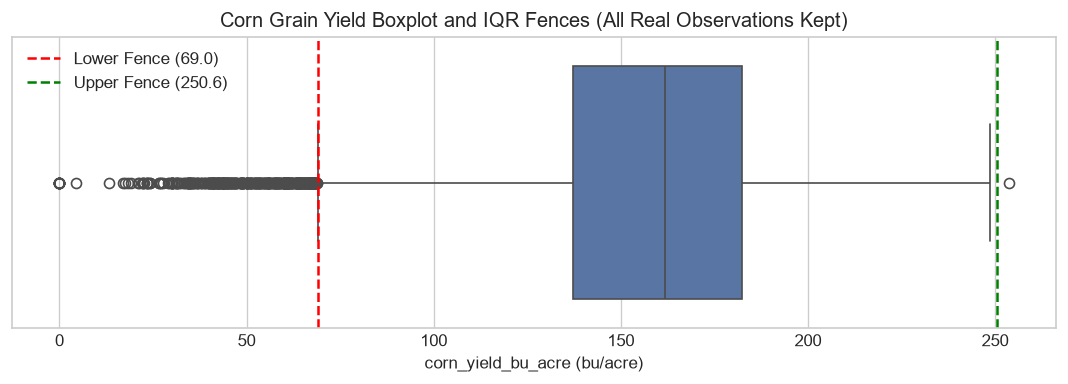

In [14]:
# 3. Check invalid values (negative yields, out-of-range years) and check IQR outliers
print("Negative yield rows:", (yield_df["corn_yield_bu_acre"] < 0).sum())
print("Yield year range:", yield_df["year"].min(), "to", yield_df["year"].max())

y_vals = yield_df["corn_yield_bu_acre"]
q1, q3 = y_vals.quantile([0.25, 0.75])
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

print(f"IQR = {iqr:.2f} | Fences: [{lower_fence:.2f}, {upper_fence:.2f}] bu/acre")
print(f"Below lower fence: {(y_vals < lower_fence).sum()} rows (including {(y_vals == 0).sum()} zero-yield records)")
print(f"Above upper fence: {(y_vals > upper_fence).sum()} rows (max = {y_vals.max():.2f} bu/acre)")

print("\nLowest yield records (kept because they represent real drought/crop failures):")
display(yield_df.nsmallest(10, "corn_yield_bu_acre")[["county_fips", "state", "county", "year", "corn_yield_bu_acre"]])

fig, ax = plt.subplots(figsize=(9, 3.3))
sns.boxplot(x=y_vals, color="#4c72b0", ax=ax)
ax.axvline(lower_fence, color="red", linestyle="--", label=f"Lower Fence ({lower_fence:.1f})")
ax.axvline(upper_fence, color="green", linestyle="--", label=f"Upper Fence ({upper_fence:.1f})")
ax.set_title("Corn Grain Yield Boxplot and IQR Fences (All Real Observations Kept)")
ax.set_xlabel("corn_yield_bu_acre (bu/acre)")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Dataset Joining (Step-by-Step)

We now join our datasets step by step starting from `yield_df` (`USDA_Yield_Cleaned.csv`), showing 4 sample rows before and after each merge, common keys, row/column counts, and unmatched records.

### Join 1: USDA NASS Yield + NOAA Climate (`one_to_one`)
We combine yield and NOAA weather using `county_fips` and `year`. A left join keeps every county-year yield observation and attaches growing-season temperature and rainfall.

In [15]:
join_log = []

def run_audited_join(left_df, right_df, keys, val_mode, stage_name, left_preview, right_preview):
    '''Merge two tables, verify row/column counts, and display sample rows.'''
    print("=" * 90)
    print(f"STAGE: {stage_name} | Keys: {keys} | Validation: {val_mode}")
    r_before, c_before = left_df.shape
    print(f"Left shape : {left_df.shape} | Right shape: {right_df.shape}")

    print("\nLeft sample (4 rows):")
    display(left_df[left_preview].head(4))
    print("Right sample (4 rows):")
    display(right_df[right_preview].head(4))

    merged = left_df.merge(right_df, on=keys, how="left", indicator=True, validate=val_mode)
    r_after, c_after = merged.shape[0], merged.shape[1] - 1  # excluding temporary _merge

    print(f"Rows before: {r_before:,} -> Rows after: {r_after:,} | Cols before: {c_before} -> Cols after: {c_after}")
    print("Match breakdown (_merge):")
    display(merged["_merge"].value_counts().rename_axis("Match_Status").to_frame("Count"))

    unmatched = merged[merged["_merge"] != "both"]
    if len(unmatched) > 0:
        print(f"Unmatched records: {len(unmatched):,}. Sample unmatched keys:")
        display(unmatched[keys].head(4))

    out_df = merged.drop(columns=["_merge"])
    print("Result after join (4 rows):")
    display(out_df[list(dict.fromkeys(left_preview + right_preview))].head(4))

    join_log.append({
        "Joining Stage": stage_name,
        "Rows Before": r_before,
        "Columns Before": c_before,
        "Rows After": r_after,
        "Columns After": c_after,
        "Join Type": "Left (1:1)" if val_mode == "one_to_one" else "Many-to-One",
    })
    return out_df


# Base table: USDA Yield
base_yield = yield_df.copy()
base_yield["state_fips"] = base_yield["county_fips"].str[:2]
base_yield = base_yield.rename(columns={"county": "county_name"})
join_log.append({
    "Joining Stage": "USDA Yield",
    "Rows Before": len(base_yield),
    "Columns Before": base_yield.shape[1],
    "Rows After": len(base_yield),
    "Columns After": base_yield.shape[1],
    "Join Type": "Base",
})

# Join 1: + NOAA Climate
noaa_cols = [c for c in noaa_df.columns if c.startswith("noaa_")]
noaa_sub = noaa_df[["county_fips", "year"] + noaa_cols].copy()

df_j1 = run_audited_join(
    base_yield, noaa_sub, ["county_fips", "year"], "one_to_one",
    "Add NOAA",
    ["county_fips", "state", "county_name", "year", "corn_yield_bu_acre"],
    ["county_fips", "year", "noaa_prcp_may_aug_in", "noaa_tmean_may_aug_f", "noaa_tmax_jul_f"],
)

STAGE: Add NOAA | Keys: ['county_fips', 'year'] | Validation: one_to_one
Left shape : (16390, 7) | Right shape: (20350, 16)

Left sample (4 rows):


,county_fips,state,county_name,year,corn_yield_bu_acre
0,17001,Illinois,Adams,2002,146.0
1,17001,Illinois,Adams,2003,171.0
2,17001,Illinois,Adams,2004,195.0
3,17001,Illinois,Adams,2005,129.0


Right sample (4 rows):


,county_fips,year,noaa_prcp_may_aug_in,noaa_tmean_may_aug_f,noaa_tmax_jul_f
0,17001,2002,22.08,71.80,88.9
1,17001,2003,15.35,70.58,85.9
2,17001,2004,20.71,69.35,82.6
3,17001,2005,10.16,72.80,89.2


Rows before: 16,390 -> Rows after: 16,390 | Cols before: 7 -> Cols after: 21
Match breakdown (_merge):


,Count
Match_Status,
both,16390
left_only,0
right_only,0


Result after join (4 rows):


,county_fips,state,county_name,year,corn_yield_bu_acre,noaa_prcp_may_aug_in,noaa_tmean_may_aug_f,noaa_tmax_jul_f
0,17001,Illinois,Adams,2002,146.0,22.08,71.80,88.9
1,17001,Illinois,Adams,2003,171.0,15.35,70.58,85.9
2,17001,Illinois,Adams,2004,195.0,20.71,69.35,82.6
3,17001,Illinois,Adams,2005,129.0,10.16,72.80,89.2


### Join 2: (USDA NASS + NOAA) + PRISM (`one_to_one`)
Next we merge `PRISM_Climate_Cleaned.csv` on `county_fips` and `year`.  
**Important limitation:** Let us verify the average `2002–2025` PRISM temperature right after merging. Historical `2002–2025` PRISM features are **full-year 12-month summaries** (including winter and post-harvest months, plus missing `2023` precipitation), whereas growing-season heat analysis requires consistent summer windows (`May–August`). Therefore, we use **NOAA monthly growing-season variables** for our 2012 analysis and exclude PRISM from the final Machine Learning feature set.

In [16]:
prism_cols = [c for c in prism_df.columns if c.startswith("prism_")]
prism_sub = prism_df[["county_fips", "year"] + prism_cols].copy()

df_j2 = run_audited_join(
    df_j1, prism_sub, ["county_fips", "year"], "one_to_one",
    "Add PRISM",
    ["county_fips", "state", "year", "corn_yield_bu_acre", "noaa_tmean_may_aug_f"],
    ["county_fips", "year", "prism_ppt_mm", "prism_tmean_c", "prism_tmax_c"],
)

print("PRISM 2002-2025 mean (full-year averages) vs NOAA May-Aug mean:")
print("  PRISM tmean_c (2002-2025):", round(df_j2["prism_tmean_c"].mean(), 2), "°C | PRISM 2026 mean:", round(prism_df.loc[prism_df["year"]==2026, "prism_tmean_c"].mean(), 2), "°C")
print("  PRISM ppt_mm nulls in 2023:", df_j2.loc[df_j2["year"]==2023, "prism_ppt_mm"].isna().sum())

STAGE: Add PRISM | Keys: ['county_fips', 'year'] | Validation: one_to_one
Left shape : (16390, 21) | Right shape: (20350, 7)

Left sample (4 rows):


,county_fips,state,year,corn_yield_bu_acre,noaa_tmean_may_aug_f
0,17001,Illinois,2002,146.0,71.80
1,17001,Illinois,2003,171.0,70.58
2,17001,Illinois,2004,195.0,69.35
3,17001,Illinois,2005,129.0,72.80


Right sample (4 rows):


,county_fips,year,prism_ppt_mm,prism_tmean_c,prism_tmax_c
0,17001,2002,1151.26,11.81,17.31
1,17001,2003,1013.78,11.01,16.49
2,17001,2004,1064.84,11.35,16.61
3,17001,2005,711.53,12.24,17.72


Rows before: 16,390 -> Rows after: 16,390 | Cols before: 21 -> Cols after: 26
Match breakdown (_merge):


,Count
Match_Status,
both,16390
left_only,0
right_only,0


Result after join (4 rows):


,county_fips,state,year,corn_yield_bu_acre,noaa_tmean_may_aug_f,prism_ppt_mm,prism_tmean_c,prism_tmax_c
0,17001,Illinois,2002,146.0,71.80,1151.26,11.81,17.31
1,17001,Illinois,2003,171.0,70.58,1013.78,11.01,16.49
2,17001,Illinois,2004,195.0,69.35,1064.84,11.35,16.61
3,17001,Illinois,2005,129.0,72.80,711.53,12.24,17.72


PRISM 2002-2025 mean (full-year averages) vs NOAA May-Aug mean:
  PRISM tmean_c (2002-2025): 9.96 °C | PRISM 2026 mean: 20.03 °C
  PRISM ppt_mm nulls in 2023: 632


### Join 3: Integrated Data + USDA RMA (`one_to_one`)
Now we join `RMA_Cleaned.csv` on `county_fips` and `year`, keeping only **pre-harvest** crop insurance variables (`policies_sold`, `net_planted_acres`, `liability_per_planted_acre`, `premium_per_planted_acre`, `subsidy`). Post-harvest indemnity and loss-ratio columns are excluded because they are only known after crop loss occurs.

In [17]:
rma_preharvest = [c for c in rma_df.columns if c.startswith("rma_") and "postharvest" not in c]
rma_sub = rma_df[["county_fips", "year"] + rma_preharvest].copy()

df_j3 = run_audited_join(
    df_j2, rma_sub, ["county_fips", "year"], "one_to_one",
    "Add RMA",
    ["county_fips", "state", "year", "corn_yield_bu_acre"],
    ["county_fips", "year", "rma_policies_sold", "rma_net_planted_acres", "rma_liability_per_planted_acre"],
)

STAGE: Add RMA | Keys: ['county_fips', 'year'] | Validation: one_to_one
Left shape : (16390, 26) | Right shape: (18817, 10)

Left sample (4 rows):


,county_fips,state,year,corn_yield_bu_acre
0,17001,Illinois,2002,146.0
1,17001,Illinois,2003,171.0
2,17001,Illinois,2004,195.0
3,17001,Illinois,2005,129.0


Right sample (4 rows):


,county_fips,year,rma_policies_sold,rma_net_planted_acres,rma_liability_per_planted_acre
0,17001,2002,1047.0,103037.0,217.16
1,17001,2003,1027.0,109830.0,229.09
2,17001,2004,1012.0,109517.0,273.85
3,17001,2005,987.0,118347.0,238.11


Rows before: 16,390 -> Rows after: 16,390 | Cols before: 26 -> Cols after: 34
Match breakdown (_merge):


,Count
Match_Status,
both,16024
left_only,366
right_only,0


Unmatched records: 366. Sample unmatched keys:


,county_fips,year
447,17043,2002
448,17043,2003
449,17043,2004
450,17043,2005


Result after join (4 rows):


,county_fips,state,year,corn_yield_bu_acre,rma_policies_sold,rma_net_planted_acres,rma_liability_per_planted_acre
0,17001,Illinois,2002,146.0,1047.0,103037.0,217.16
1,17001,Illinois,2003,171.0,1027.0,109830.0,229.09
2,17001,Illinois,2004,195.0,1012.0,109517.0,273.85
3,17001,Illinois,2005,129.0,987.0,118347.0,238.11


### Join 4: Integrated Data + SoilGrids (`many_to_one`)
SoilGrids has one static soil profile per county (`county_fips`), while our main dataset has multiple yearly yield records for each county. Therefore, this relationship is **`many_to_one`**: the same county soil values naturally repeat across multiple years for that county. First we compute depth-weighted `0–30 cm` soil averages (`5/30` for `0–5 cm`, `10/30` for `5–15 cm`, `15/30` for `15–30 cm`).

In [18]:
soil_work = soil_df.copy()
soil_work["soil_clay_mean_0_30cm"] = (soil_work["clay_0_5cm"]*5 + soil_work["clay_5_15cm"]*10 + soil_work["clay_15_30cm"]*15) / 30.0
soil_work["soil_sand_mean_0_30cm"] = (soil_work["sand_0_5cm"]*5 + soil_work["sand_5_15cm"]*10 + soil_work["sand_15_30cm"]*15) / 30.0
soil_work["soil_silt_mean_0_30cm"] = (soil_work["silt_0_5cm"]*5 + soil_work["silt_5_15cm"]*10 + soil_work["silt_15_30cm"]*15) / 30.0
soil_work["soil_soc_mean_0_30cm"]  = (soil_work["soc_0_5cm"]*5  + soil_work["soc_5_15cm"]*10  + soil_work["soc_15_30cm"]*15) / 30.0
soil_work["soil_ph_mean_0_30cm"]   = (soil_work["phh2o_0_5cm"]*5 + soil_work["phh2o_5_15cm"]*10 + soil_work["phh2o_15_30cm"]*15) / 30.0
soil_work["soil_bdod_mean_0_30cm"] = (soil_work["bdod_0_5cm"]*5 + soil_work["bdod_5_15cm"]*10 + soil_work["bdod_15_30cm"]*15) / 30.0

soil_sub = soil_work[[
    "county_fips", "intptlat", "intptlon",
    "soil_clay_mean_0_30cm", "soil_sand_mean_0_30cm", "soil_silt_mean_0_30cm",
    "soil_soc_mean_0_30cm", "soil_ph_mean_0_30cm", "soil_bdod_mean_0_30cm"
]].rename(columns={"intptlat": "soil_intptlat", "intptlon": "soil_intptlon"})

df_j4 = run_audited_join(
    df_j3, soil_sub, ["county_fips"], "many_to_one",
    "Add SoilGrids",
    ["county_fips", "state", "year", "corn_yield_bu_acre"],
    ["county_fips", "soil_soc_mean_0_30cm", "soil_clay_mean_0_30cm", "soil_ph_mean_0_30cm"],
)

STAGE: Add SoilGrids | Keys: ['county_fips'] | Validation: many_to_one
Left shape : (16390, 34) | Right shape: (814, 9)

Left sample (4 rows):


,county_fips,state,year,corn_yield_bu_acre
0,17001,Illinois,2002,146.0
1,17001,Illinois,2003,171.0
2,17001,Illinois,2004,195.0
3,17001,Illinois,2005,129.0


Right sample (4 rows):


,county_fips,soil_soc_mean_0_30cm,soil_clay_mean_0_30cm,soil_ph_mean_0_30cm
0,17001,1.430000,30.656667,6.021667
1,17003,1.645000,24.255000,5.593333
2,17005,1.316667,26.540000,6.158333
3,17007,2.281667,32.656667,6.341667


Rows before: 16,390 -> Rows after: 16,390 | Cols before: 34 -> Cols after: 42
Match breakdown (_merge):


,Count
Match_Status,
both,16390
left_only,0
right_only,0


Result after join (4 rows):


,county_fips,state,year,corn_yield_bu_acre,soil_soc_mean_0_30cm,soil_clay_mean_0_30cm,soil_ph_mean_0_30cm
0,17001,Illinois,2002,146.0,1.43,30.656667,6.021667
1,17001,Illinois,2003,171.0,1.43,30.656667,6.021667
2,17001,Illinois,2004,195.0,1.43,30.656667,6.021667
3,17001,Illinois,2005,129.0,1.43,30.656667,6.021667


### Join 5: Crop Condition + Crop Progress (`state_fips`, `year`)
`Crop_Condition_Cleaned.csv` and `Crop_Progress_Cleaned.csv` are recorded at the **state-year** level. First we join them together on `["state_fips", "year"]` (`one_to_one`), and then we attach that state-level table to our county-year dataset (`many_to_one`). Every county in the same state and year shares the same state-level crop condition and progress values—these are state-level context variables, not independent county measurements.

In [19]:
cond_cols = [c for c in cond_df.columns if c.startswith("state_cond_")]
prog_cols = [c for c in prog_df.columns if c.startswith("state_progress_") and "postharvest" not in c]

state_survey_df = cond_df[["state_fips", "year"] + cond_cols].merge(
    prog_df[["state_fips", "year"] + prog_cols],
    on=["state_fips", "year"],
    how="inner",
    validate="one_to_one",
)

master_df = run_audited_join(
    df_j4, state_survey_df, ["state_fips", "year"], "many_to_one",
    "Add Crop Condition/Progress",
    ["county_fips", "state_fips", "state", "year", "corn_yield_bu_acre"],
    ["state_fips", "year", "state_cond_rep_good_excellent_mean", "state_progress_planted_w20_pct", "state_progress_silking_w30_pct"],
)

STAGE: Add Crop Condition/Progress | Keys: ['state_fips', 'year'] | Validation: many_to_one
Left shape : (16390, 42) | Right shape: (225, 20)

Left sample (4 rows):


,county_fips,state_fips,state,year,corn_yield_bu_acre
0,17001,17,Illinois,2002,146.0
1,17001,17,Illinois,2003,171.0
2,17001,17,Illinois,2004,195.0
3,17001,17,Illinois,2005,129.0


Right sample (4 rows):


,state_fips,year,state_cond_rep_good_excellent_mean,state_progress_planted_w20_pct,state_progress_silking_w30_pct
0,19,2002,61.71,94.0,86.0
1,19,2003,73.43,79.0,67.0
2,19,2004,76.29,98.0,73.0
3,19,2005,68.00,98.0,93.0


Rows before: 16,390 -> Rows after: 16,390 | Cols before: 42 -> Cols after: 60
Match breakdown (_merge):


,Count
Match_Status,
both,16390
left_only,0
right_only,0


Result after join (4 rows):


,county_fips,state_fips,state,year,corn_yield_bu_acre,state_cond_rep_good_excellent_mean,state_progress_planted_w20_pct,state_progress_silking_w30_pct
0,17001,17,Illinois,2002,146.0,37.71,51.0,86.0
1,17001,17,Illinois,2003,171.0,76.14,79.0,84.0
2,17001,17,Illinois,2004,195.0,83.29,98.0,97.0
3,17001,17,Illinois,2005,129.0,12.29,99.0,99.0


## 7. Final Integrated Dataset and Column Cleanup

Below is the mandatory joining summary across every stage, key integrity checks on `master_df`, and the table of unnecessary or unsuitable columns removed before analysis and modeling.

In [20]:
join_summary_df = pd.DataFrame(join_log)
display(join_summary_df)

print("Final master_df shape:", master_df.shape)
print("Duplicate (county_fips, year) records:", master_df.duplicated(subset=["county_fips", "year"]).sum())
print("Missing county_fips values:", master_df["county_fips"].isna().sum())
print("All columns:", master_df.columns.tolist())
display(master_df.head())

,Joining Stage,Rows Before,Columns Before,Rows After,Columns After,Join Type
0,USDA Yield,16390,7,16390,7,Base
1,Add NOAA,16390,7,16390,21,Left (1:1)
2,Add PRISM,16390,21,16390,26,Left (1:1)
3,Add RMA,16390,26,16390,34,Left (1:1)
4,Add SoilGrids,16390,34,16390,42,Many-to-One
5,Add Crop Condition/Progress,16390,42,16390,60,Many-to-One


Final master_df shape: (16390, 60)
Duplicate (county_fips, year) records: 0
Missing county_fips values: 0
All columns: ['county_fips', 'state', 'county_name', 'year', 'corn_yield_bu_acre', 'cv_percent', 'state_fips', 'noaa_prcp_may_in', 'noaa_prcp_jun_in', 'noaa_prcp_jul_in', 'noaa_prcp_aug_in', 'noaa_prcp_sep_in', 'noaa_prcp_may_aug_in', 'noaa_prcp_may_sep_in', 'noaa_prcp_annual_in', 'noaa_tmean_may_aug_f', 'noaa_tmax_jul_f', 'noaa_tmax_aug_f', 'noaa_tmax_may_aug_f', 'noaa_tmin_may_aug_f', 'noaa_heat_stress_max_f', 'prism_ppt_mm', 'prism_tmean_c', 'prism_tmin_c', 'prism_tmax_c', 'prism_valid_coverage_pct', 'rma_policies_sold', 'rma_policies_earning_prem', 'rma_net_planted_acres', 'rma_liability_total', 'rma_total_premium', 'rma_subsidy', 'rma_liability_per_planted_acre', 'rma_premium_per_planted_acre', 'soil_intptlat', 'soil_intptlon', 'soil_clay_mean_0_30cm', 'soil_sand_mean_0_30cm', 'soil_silt_mean_0_30cm', 'soil_soc_mean_0_30cm', 'soil_ph_mean_0_30cm', 'soil_bdod_mean_0_30cm', 'sta

,county_fips,state,county_name,year,corn_yield_bu_acre,cv_percent,state_fips,noaa_prcp_may_in,noaa_prcp_jun_in,noaa_prcp_jul_in,...,state_cond_rep_poor_very_poor_mean,state_progress_planted_w20_pct,state_progress_emerged_w22_pct,state_progress_silking_w30_pct,state_progress_dough_w34_pct,state_progress_dented_w37_pct,state_progress_mature_w40_pct,state_progress_week_50pct_planted,state_progress_week_50pct_silking,state_progress_week_50pct_mature
0,17001,Illinois,Adams,2002,146.0,NaN,17,9.02,4.27,4.05,...,24.57,51.0,68.0,86.0,90.0,92.0,95.0,19.0,29.0,38.0
1,17001,Illinois,Adams,2003,171.0,NaN,17,3.37,4.04,5.00,...,6.00,79.0,86.0,84.0,88.0,91.0,95.0,18.0,29.0,38.0
2,17001,Illinois,Adams,2004,195.0,NaN,17,5.06,3.11,3.33,...,3.29,98.0,97.0,97.0,95.0,95.0,97.0,17.0,28.0,38.0
3,17001,Illinois,Adams,2005,129.0,NaN,17,1.60,2.68,1.55,...,57.57,99.0,99.0,99.0,97.0,97.0,99.0,16.0,27.0,36.0
4,17001,Illinois,Adams,2006,129.0,NaN,17,1.59,3.53,2.79,...,8.29,96.0,97.0,98.0,95.0,98.0,99.0,17.0,28.0,37.0


In [21]:
# Remove columns that are mostly empty, post-harvest, or time-mismatched before modeling
removed_specs = [
    ("cv_percent", "77.2% missing in USDA NASS yield survey"),
    ("noaa_prcp_annual_in", "Full-year precipitation includes post-harvest Oct–Dec weather"),
    ("prism_ppt_mm", "Annual 12-month total in 2002–2025 + entirely missing in 2023"),
    ("prism_tmean_c", "Annual 12-month average in 2002–2025 (mismatched with 2026 May–Oct)"),
    ("prism_tmin_c", "Annual 12-month average in 2002–2025 (includes winter months)"),
    ("prism_tmax_c", "Annual 12-month average in 2002–2025 (includes winter months)"),
    ("prism_valid_coverage_pct", "Raster extraction coverage metadata, not an agro-climatic feature"),
]

# Also note post-harvest columns excluded earlier during Joins 3 & 5
excluded_earlier = [
    ("rma_postharvest_policies_indemnified", "Post-harvest insurance claim count (target leakage)"),
    ("rma_postharvest_indemnity_amount", "Post-harvest indemnity payout (target leakage)"),
    ("rma_postharvest_loss_ratio", "Post-harvest loss ratio (target leakage)"),
    ("state_progress_postharvest_harvested_w44_pct", "Week 44 post-harvest completion (target leakage)"),
]

removed_table = pd.DataFrame(removed_specs + excluded_earlier, columns=["Removed Column", "Reason"])
display(removed_table)

cols_to_drop = [col for col, _ in removed_specs if col in master_df.columns]
clean_df = master_df.drop(columns=cols_to_drop).copy()
print(f"Cleaned integrated dataset shape (keeping identifiers + corn_yield_bu_acre): {clean_df.shape}")

,Removed Column,Reason
0,cv_percent,77.2% missing in USDA NASS yield survey
1,noaa_prcp_annual_in,Full-year precipitation includes post-harvest ...
2,prism_ppt_mm,Annual 12-month total in 2002–2025 + entirely ...
3,prism_tmean_c,Annual 12-month average in 2002–2025 (mismatch...
4,prism_tmin_c,Annual 12-month average in 2002–2025 (includes...
5,prism_tmax_c,Annual 12-month average in 2002–2025 (includes...
6,prism_valid_coverage_pct,"Raster extraction coverage metadata, not an ag..."
7,rma_postharvest_policies_indemnified,Post-harvest insurance claim count (target lea...
8,rma_postharvest_indemnity_amount,Post-harvest indemnity payout (target leakage)
9,rma_postharvest_loss_ratio,Post-harvest loss ratio (target leakage)


Cleaned integrated dataset shape (keeping identifiers + corn_yield_bu_acre): (16390, 53)


## 8. Exploratory Data Analysis

We explore the cleaned integrated dataset (`clean_df`, `2002–2025`) across yield, temperature, rainfall, soil properties, and their relationships.

### 8.1 Yield Analysis & 8.2 Temperature Analysis

Yield summary (bu/acre):


,count,mean,std,min,25%,50%,75%,max
corn_yield_bu_acre,16390.0,157.45,36.25,0.0,137.1,161.9,182.5,253.6


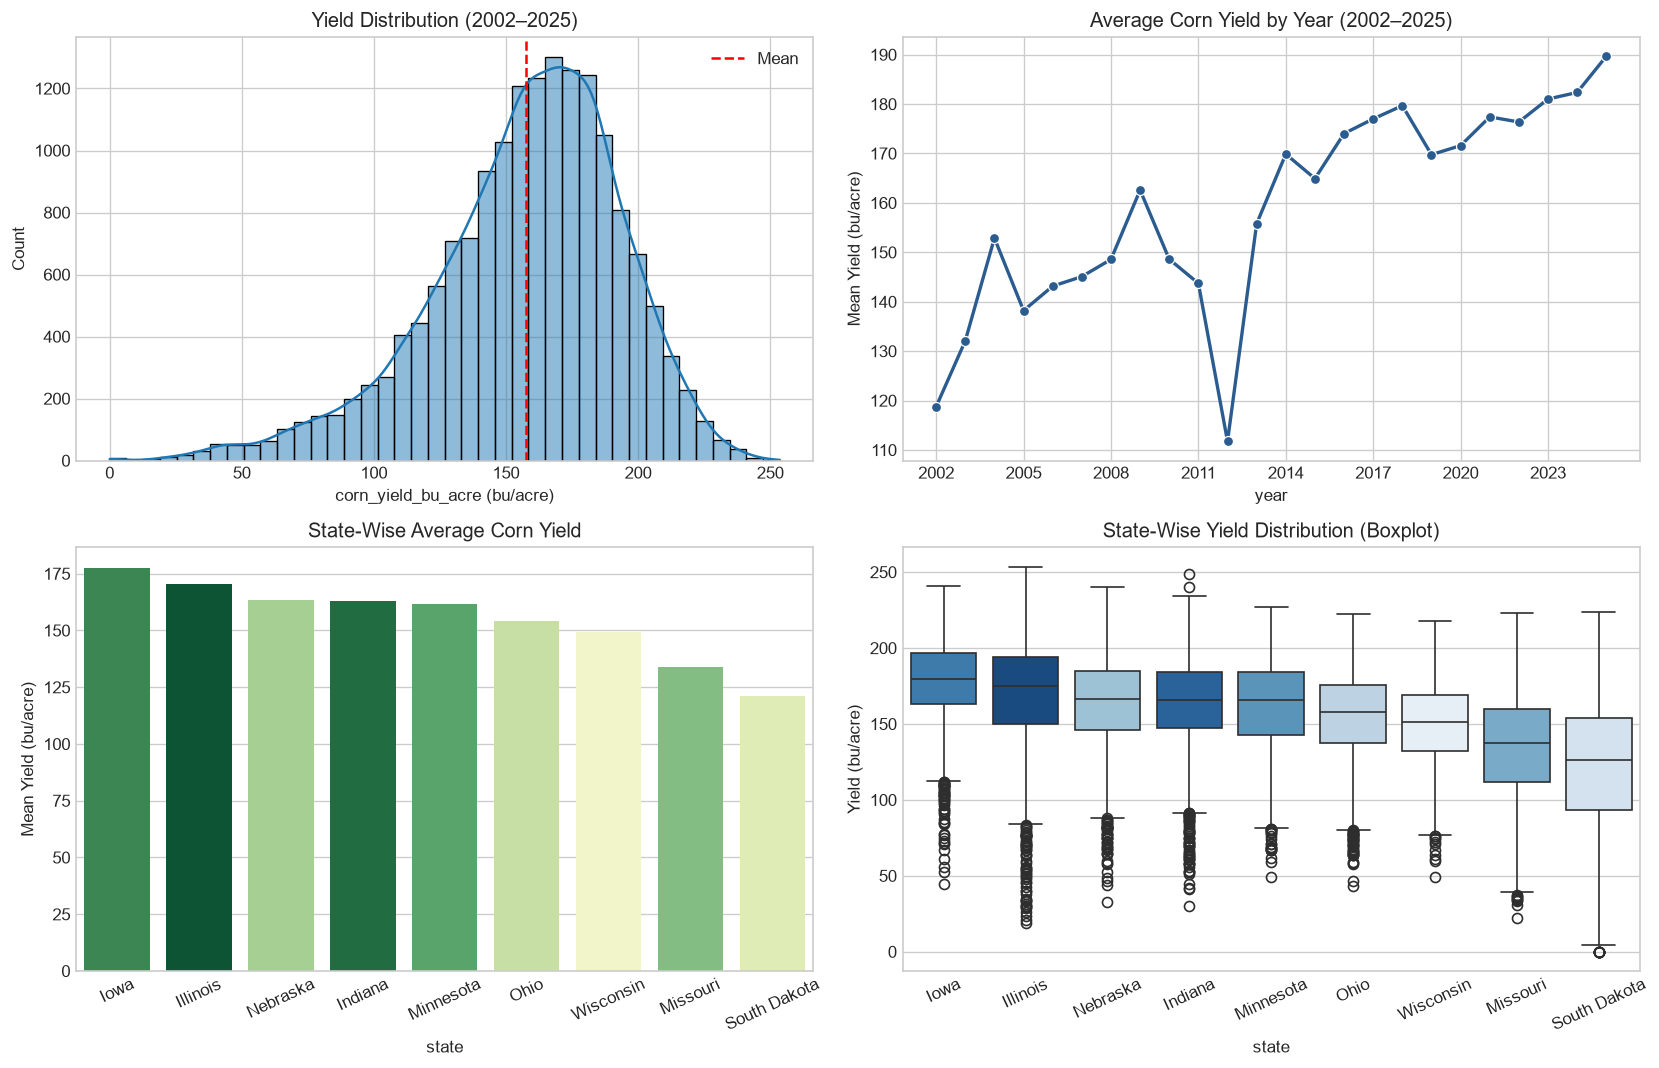

In [22]:
print("Yield summary (bu/acre):")
display(clean_df["corn_yield_bu_acre"].describe().round(2).to_frame().T)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Yield distribution
sns.histplot(clean_df["corn_yield_bu_acre"], bins=40, kde=True, color="#1f78b4", ax=axes[0, 0])
axes[0, 0].axvline(clean_df["corn_yield_bu_acre"].mean(), color="red", linestyle="--", label="Mean")
axes[0, 0].set_title("Yield Distribution (2002–2025)")
axes[0, 0].set_xlabel("corn_yield_bu_acre (bu/acre)")
axes[0, 0].legend()

# Average yield by year
yr_yield = clean_df.groupby("year")["corn_yield_bu_acre"].mean().reset_index()
sns.lineplot(data=yr_yield, x="year", y="corn_yield_bu_acre", marker="o", color="#2b5c8f", lw=2, ax=axes[0, 1])
axes[0, 1].set_title("Average Corn Yield by Year (2002–2025)")
axes[0, 1].set_ylabel("Mean Yield (bu/acre)")
axes[0, 1].set_xticks(range(2002, 2026, 3))

# State-wise average yield
st_order = clean_df.groupby("state")["corn_yield_bu_acre"].mean().sort_values(ascending=False).index
sns.barplot(data=clean_df, x="state", y="corn_yield_bu_acre", order=st_order, hue="state", palette="YlGn_r", legend=False, errorbar=None, ax=axes[1, 0])
axes[1, 0].set_title("State-Wise Average Corn Yield")
axes[1, 0].set_ylabel("Mean Yield (bu/acre)")
axes[1, 0].tick_params(axis="x", rotation=25)

# Boxplot of yield by state
sns.boxplot(data=clean_df, x="state", y="corn_yield_bu_acre", order=st_order, hue="state", palette="Blues_r", legend=False, ax=axes[1, 1])
axes[1, 1].set_title("State-Wise Yield Distribution (Boxplot)")
axes[1, 1].set_ylabel("Yield (bu/acre)")
axes[1, 1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_yield_overview.png", dpi=130)
plt.show()

**What the yield charts show:**  
Corn yield averages rise across `2002–2025`, with a sharp drop in `2012`. Iowa, Illinois, and Indiana achieve higher average yields than South Dakota and Missouri, which also show wider county-to-county spread.

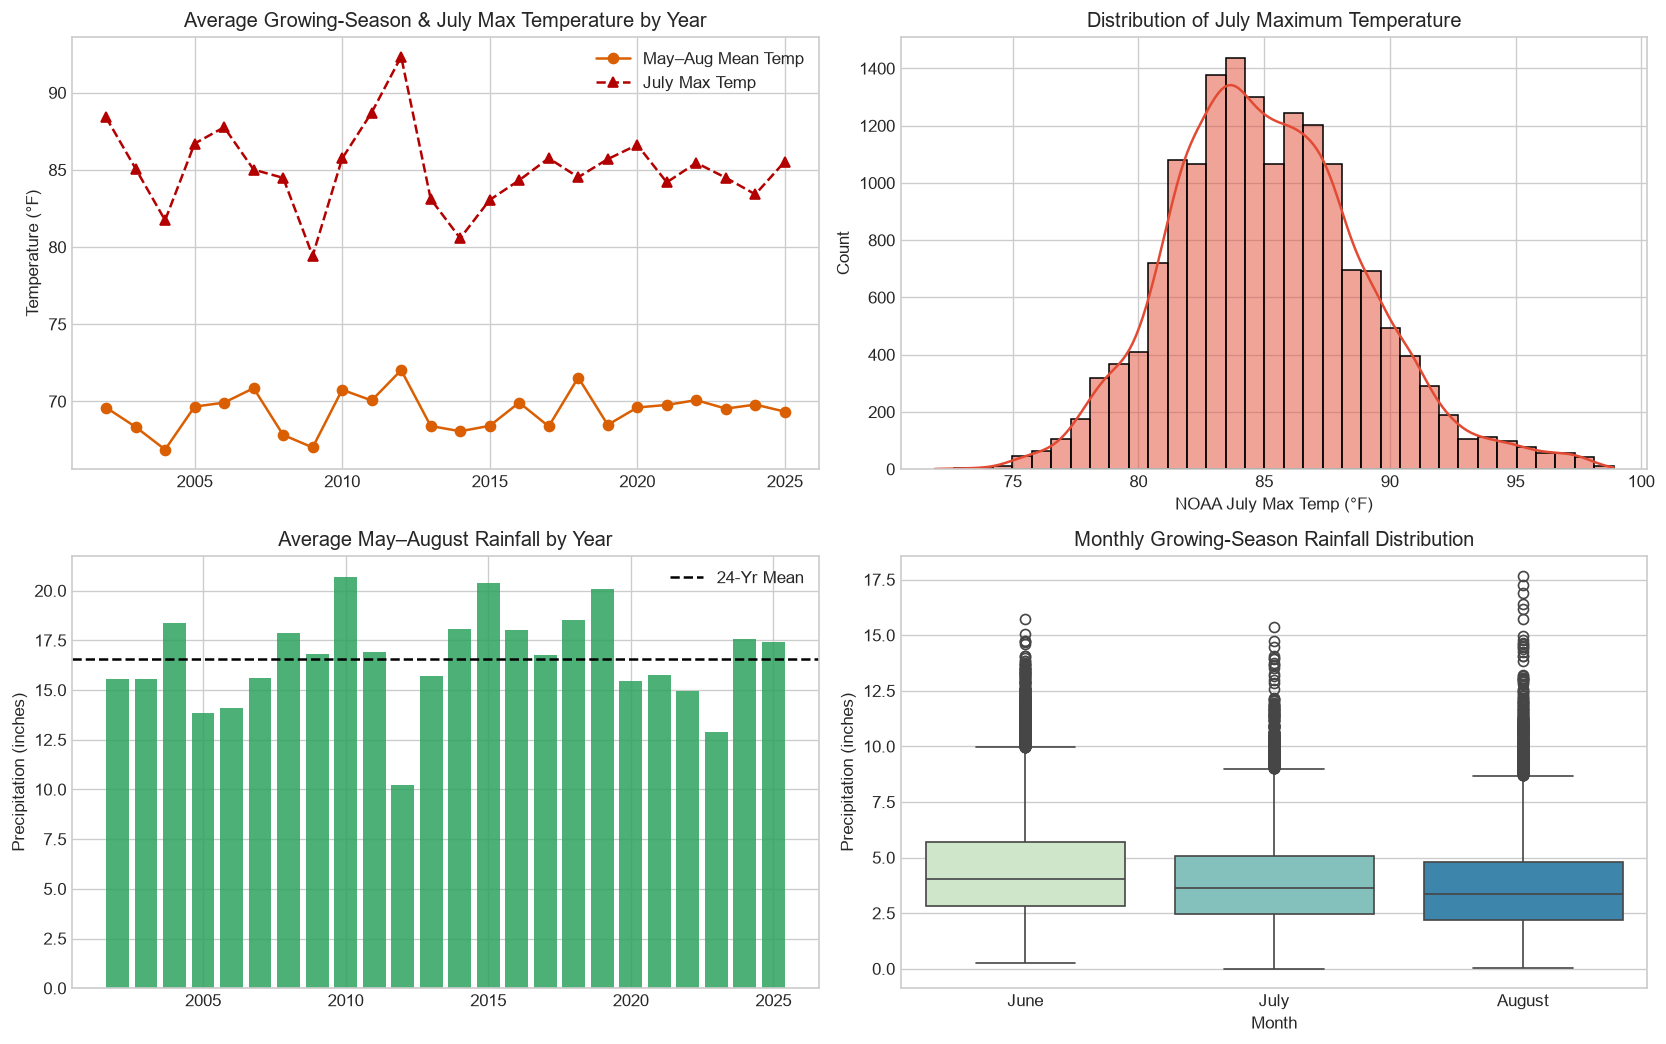

In [23]:
# Temperature & Rainfall Analysis (8.2 & 8.3)
fig, axes = plt.subplots(2, 2, figsize=(14, 8.8))

yr_clim = clean_df.groupby("year").agg(
    tmean=("noaa_tmean_may_aug_f", "mean"),
    tmax_jul=("noaa_tmax_jul_f", "mean"),
    prcp_may_aug=("noaa_prcp_may_aug_in", "mean"),
).reset_index()

# Temp by year
axes[0, 0].plot(yr_clim["year"], yr_clim["tmean"], marker="o", label="May–Aug Mean Temp", color="#d95f02")
axes[0, 0].plot(yr_clim["year"], yr_clim["tmax_jul"], marker="^", linestyle="--", label="July Max Temp", color="#b30000")
axes[0, 0].set_title("Average Growing-Season & July Max Temperature by Year")
axes[0, 0].set_ylabel("Temperature (°F)")
axes[0, 0].legend()

# Temp distribution
sns.histplot(clean_df["noaa_tmax_jul_f"], bins=35, kde=True, color="#e34a33", ax=axes[0, 1])
axes[0, 1].set_title("Distribution of July Maximum Temperature")
axes[0, 1].set_xlabel("NOAA July Max Temp (°F)")

# Rainfall by year
axes[1, 0].bar(yr_clim["year"], yr_clim["prcp_may_aug"], color="#2ca25f", alpha=0.85)
axes[1, 0].axhline(yr_clim["prcp_may_aug"].mean(), color="black", linestyle="--", label="24-Yr Mean")
axes[1, 0].set_title("Average May–August Rainfall by Year")
axes[1, 0].set_ylabel("Precipitation (inches)")
axes[1, 0].legend()

# Monthly rainfall distribution (Jun, Jul, Aug)
rain_melt = clean_df[["noaa_prcp_jun_in", "noaa_prcp_jul_in", "noaa_prcp_aug_in"]].rename(columns={
    "noaa_prcp_jun_in": "June", "noaa_prcp_jul_in": "July", "noaa_prcp_aug_in": "August"
}).melt(var_name="Month", value_name="Rainfall_in")
sns.boxplot(data=rain_melt, x="Month", y="Rainfall_in", hue="Month", palette="GnBu", legend=False, ax=axes[1, 1])
axes[1, 1].set_title("Monthly Growing-Season Rainfall Distribution")
axes[1, 1].set_ylabel("Precipitation (inches)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_temperature_rainfall.png", dpi=130)
plt.show()

### 8.4 Soil Analysis & 8.5 Relationship Analysis
Below we inspect the distributions of our 0–30 cm SoilGrids features (`SOC`, `pH`, `clay`, `sand`, `silt`), scatter relationships with yield, and the overall correlation heatmap.

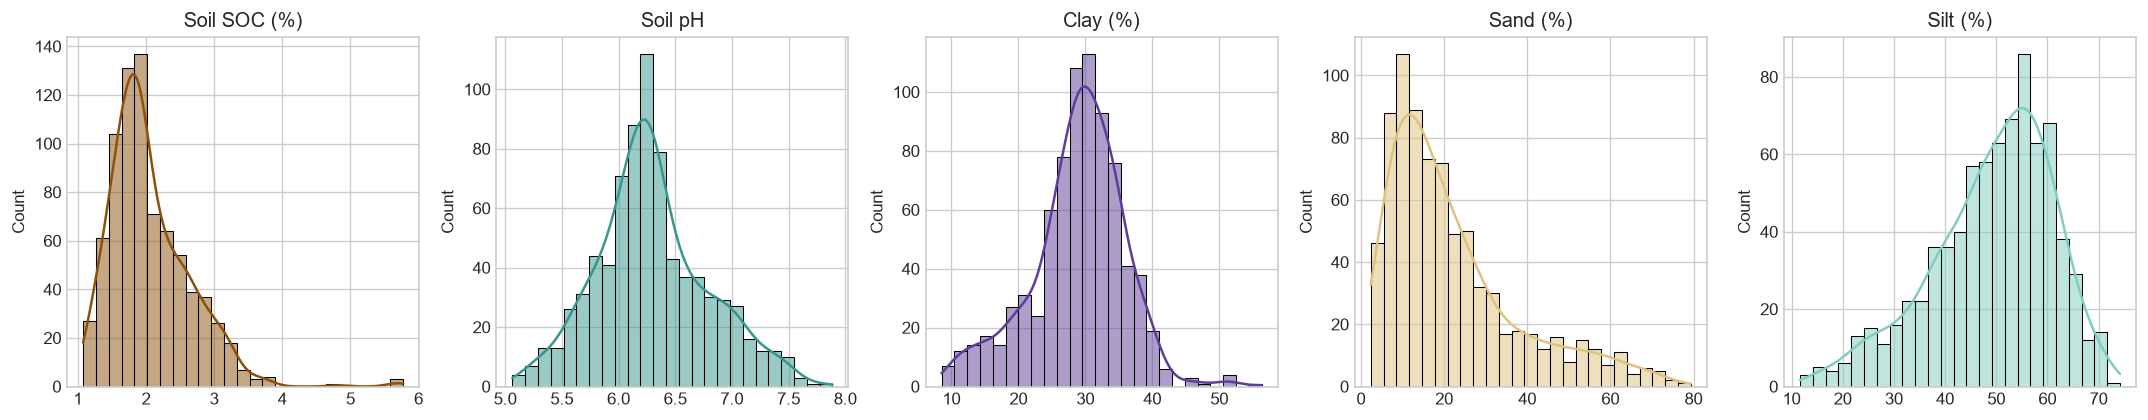

In [24]:
# Soil distributions across unique counties
county_soil = clean_df.groupby("county_fips")[[
    "soil_soc_mean_0_30cm", "soil_ph_mean_0_30cm",
    "soil_clay_mean_0_30cm", "soil_sand_mean_0_30cm", "soil_silt_mean_0_30cm"
]].first().dropna()

fig, axes = plt.subplots(1, 5, figsize=(18, 3.6))
for ax, col, title, colhex in zip(
    axes,
    county_soil.columns,
    ["Soil SOC (%)", "Soil pH", "Clay (%)", "Sand (%)", "Silt (%)"],
    ["#8c510a", "#35978f", "#5e3c99", "#dfc27d", "#80cdc1"],
):
    sns.histplot(county_soil[col], bins=25, kde=True, color=colhex, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_soil_distributions.png", dpi=130)
plt.show()

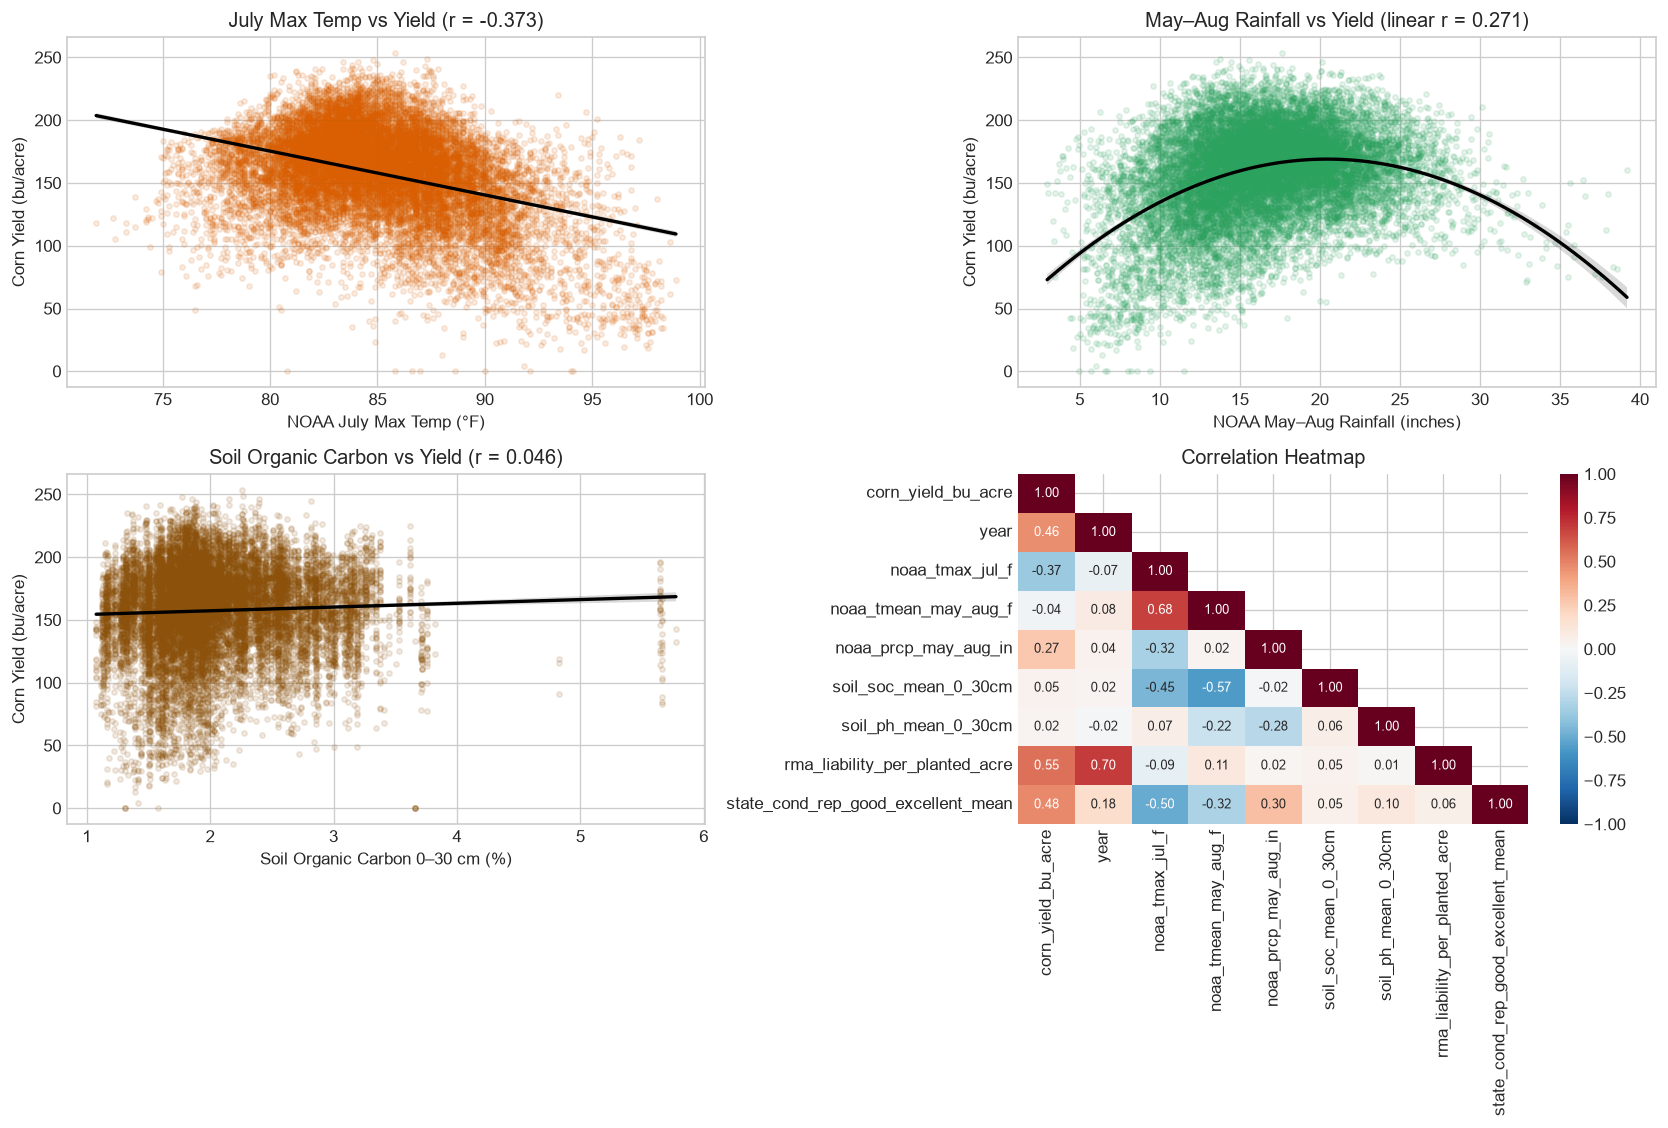

In [25]:
# Scatter relationships + Correlation heatmap
fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))

r_temp, _ = stats.pearsonr(clean_df["noaa_tmax_jul_f"], clean_df["corn_yield_bu_acre"])
sns.regplot(data=clean_df, x="noaa_tmax_jul_f", y="corn_yield_bu_acre", ax=axes[0, 0],
            scatter_kws={"alpha": 0.12, "s": 10, "color": "#d95f02"}, line_kws={"color": "black", "lw": 2})
axes[0, 0].set_title(f"July Max Temp vs Yield (r = {r_temp:.3f})")
axes[0, 0].set_xlabel("NOAA July Max Temp (°F)")
axes[0, 0].set_ylabel("Corn Yield (bu/acre)")

r_rain, _ = stats.pearsonr(clean_df["noaa_prcp_may_aug_in"], clean_df["corn_yield_bu_acre"])
sns.regplot(data=clean_df, x="noaa_prcp_may_aug_in", y="corn_yield_bu_acre", order=2, ax=axes[0, 1],
            scatter_kws={"alpha": 0.12, "s": 10, "color": "#2ca25f"}, line_kws={"color": "black", "lw": 2})
axes[0, 1].set_title(f"May–Aug Rainfall vs Yield (linear r = {r_rain:.3f})")
axes[0, 1].set_xlabel("NOAA May–Aug Rainfall (inches)")
axes[0, 1].set_ylabel("Corn Yield (bu/acre)")

sub_soc = clean_df[["soil_soc_mean_0_30cm", "corn_yield_bu_acre"]].dropna()
r_soc, _ = stats.pearsonr(sub_soc["soil_soc_mean_0_30cm"], sub_soc["corn_yield_bu_acre"])
sns.regplot(data=sub_soc, x="soil_soc_mean_0_30cm", y="corn_yield_bu_acre", ax=axes[1, 0],
            scatter_kws={"alpha": 0.12, "s": 10, "color": "#8c510a"}, line_kws={"color": "black", "lw": 2})
axes[1, 0].set_title(f"Soil Organic Carbon vs Yield (r = {r_soc:.3f})")
axes[1, 0].set_xlabel("Soil Organic Carbon 0–30 cm (%)")
axes[1, 0].set_ylabel("Corn Yield (bu/acre)")

heat_cols = [
    "corn_yield_bu_acre", "year", "noaa_tmax_jul_f", "noaa_tmean_may_aug_f",
    "noaa_prcp_may_aug_in", "soil_soc_mean_0_30cm", "soil_ph_mean_0_30cm",
    "rma_liability_per_planted_acre", "state_cond_rep_good_excellent_mean"
]
corr_mat = clean_df[heat_cols].corr()
mask = np.triu(np.ones_like(corr_mat, dtype=bool), k=1)
sns.heatmap(corr_mat, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 7.5}, ax=axes[1, 1])
axes[1, 1].set_title("Correlation Heatmap")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_relationships_and_heatmap.png", dpi=130)
plt.show()

**What these relationship plots show:**  
Higher July maximum temperature correlates negatively with corn yield, whereas growing-season rainfall and soil organic carbon correlate positively with yield. State crop condition ratings and pre-harvest insurance liability per acre also correlate positively with yield. Note that correlations show association in historical observations and do not prove causation by themselves.

## 9. 2012 Midwest Drought and Heat Impact on Maize Yield

To understand why maize yield fell so sharply in `2012`, we conduct a focused year-to-year analysis across our county-level dataset, comparing `2011`, `2012`, and `2013` as well as `2012` temperature and rainfall anomalies relative to `2002–2011` county baselines.

### 9.1 Consistent-County Comparison: 2011 vs. 2012 vs. 2013
To avoid bias from counties that did not report in one of the three years, we restrict this comparison to counties that reported yield in **all three years (`2011`, `2012`, and `2013`)**.

In [26]:
# Find counties present in 2011, 2012, and 2013
c2011 = set(clean_df.loc[clean_df["year"] == 2011, "county_fips"])
c2012 = set(clean_df.loc[clean_df["year"] == 2012, "county_fips"])
c2013 = set(clean_df.loc[clean_df["year"] == 2013, "county_fips"])
consistent_counties = c2011 & c2012 & c2013

panel_11_13 = clean_df[
    (clean_df["year"].isin([2011, 2012, 2013])) &
    (clean_df["county_fips"].isin(consistent_counties))
].copy()

tbl_11_13 = panel_11_13.groupby("year").agg(
    Number_of_Counties=("county_fips", "nunique"),
    Average_Yield=("corn_yield_bu_acre", "mean"),
    July_Maximum_Temp=("noaa_tmax_jul_f", "mean"),
    May_Aug_Rainfall=("noaa_prcp_may_aug_in", "mean"),
).round(2).reset_index()

y11 = tbl_11_13.loc[tbl_11_13["year"] == 2011, "Average_Yield"].values[0]
y12 = tbl_11_13.loc[tbl_11_13["year"] == 2012, "Average_Yield"].values[0]
y13 = tbl_11_13.loc[tbl_11_13["year"] == 2013, "Average_Yield"].values[0]

pct_11_12 = ((y12 - y11) / y11) * 100
pct_12_13 = ((y13 - y12) / y12) * 100

tbl_11_13.to_csv(OUTPUT_DIR / "drought_2012_summary.csv", index=False)
display(tbl_11_13)
print(f"Consistent-county yield change 2011 -> 2012: {y12 - y11:+.2f} bu/acre ({pct_11_12:+.2f}%)")
print(f"Consistent-county yield recovery 2012 -> 2013: {y13 - y12:+.2f} bu/acre ({pct_12_13:+.2f}%)")

,year,Number_of_Counties,Average_Yield,July_Maximum_Temp,May_Aug_Rainfall
0,2011,629,146.60,88.55,16.93
1,2012,629,115.12,92.20,10.34
2,2013,629,157.40,83.07,15.62


Consistent-county yield change 2011 -> 2012: -31.48 bu/acre (-21.47%)
Consistent-county yield recovery 2012 -> 2013: +42.28 bu/acre (+36.73%)


### 9.2 State-Wise 2012 Comparison & 9.3 County-Level Yield Loss
Below we compare `2011` and `2012` yields alongside `2012` July temperature and May–August rainfall across all nine Corn Belt states, and then examine the counties with the largest yield losses and the most stable yields.

In [27]:
# Merge 2011 and 2012 county records on county_fips
df_2011 = clean_df[clean_df["year"] == 2011][["county_fips", "state", "county_name", "corn_yield_bu_acre"]].rename(
    columns={"corn_yield_bu_acre": "yield_2011"}
)
df_2012 = clean_df[clean_df["year"] == 2012][[
    "county_fips", "corn_yield_bu_acre", "noaa_tmax_jul_f", "noaa_tmax_aug_f",
    "noaa_tmean_may_aug_f", "noaa_prcp_jun_in", "noaa_prcp_jul_in", "noaa_prcp_aug_in", "noaa_prcp_may_aug_in"
]].rename(columns={"corn_yield_bu_acre": "yield_2012"})

comp_11_12 = df_2011.merge(df_2012, on="county_fips", how="inner")
comp_11_12["yield_change"] = comp_11_12["yield_2012"] - comp_11_12["yield_2011"]
comp_11_12["pct_change"] = np.where(
    comp_11_12["yield_2011"] > 0,
    (comp_11_12["yield_change"] / comp_11_12["yield_2011"]) * 100.0,
    np.nan,
)

# 9.2 State-wise summary
state_2012 = comp_11_12.groupby("state").agg(
    Counties=("county_fips", "count"),
    Yield_2011=("yield_2011", "mean"),
    Yield_2012=("yield_2012", "mean"),
    Yield_Diff=("yield_change", "mean"),
    Pct_Change=("pct_change", "mean"),
    July_Tmax_2012=("noaa_tmax_jul_f", "mean"),
    MayAug_Rain_2012=("noaa_prcp_may_aug_in", "mean"),
).round(2).sort_values("Yield_Diff")

state_2012.to_csv(OUTPUT_DIR / "drought_2012_state_comparison.csv")
print("9.2 State-Wise Comparison (2011 vs 2012):")
display(state_2012)

# 9.3 County-level extremes
print("\n9.3 Top 10 Counties with Largest Yield Decline (2012 vs 2011):")
display(comp_11_12.nsmallest(10, "yield_change")[["county_fips", "state", "county_name", "yield_2011", "yield_2012", "yield_change", "pct_change", "noaa_tmax_jul_f", "noaa_prcp_may_aug_in"]].round(2))

print("Counties with Smallest Decline / Most Stable or Positive Yield Change (2012 vs 2011):")
display(comp_11_12.nlargest(10, "yield_change")[["county_fips", "state", "county_name", "yield_2011", "yield_2012", "yield_change", "pct_change", "noaa_tmax_jul_f", "noaa_prcp_may_aug_in"]].round(2))

9.2 State-Wise Comparison (2011 vs 2012):


,Counties,Yield_2011,Yield_2012,Yield_Diff,Pct_Change,July_Tmax_2012,MayAug_Rain_2012
state,,,,,,,
Illinois,88,151.05,92.85,-58.20,-40.48,94.69,8.78
Indiana,78,139.96,93.14,-46.81,-33.99,92.62,10.73
Missouri,68,107.83,67.53,-40.30,-32.17,96.86,7.75
South Dakota,52,123.22,87.53,-35.69,-29.61,92.69,8.18
Iowa,99,164.77,130.33,-34.44,-21.05,92.04,10.45
Ohio,76,148.23,119.16,-29.07,-19.57,89.24,12.11
Wisconsin,60,148.21,121.15,-27.06,-17.29,88.26,12.97
Nebraska,84,154.30,134.19,-20.11,-12.96,95.23,6.78
Minnesota,71,147.45,159.75,12.29,9.86,87.71,15.19



9.3 Top 10 Counties with Largest Yield Decline (2012 vs 2011):


,county_fips,state,county_name,yield_2011,yield_2012,yield_change,pct_change,noaa_tmax_jul_f,noaa_prcp_may_aug_in
50,17121,Illinois,Marion,139.1,19.0,-120.1,-86.34,96.5,8.65
33,17079,Illinois,Jasper,146.0,28.9,-117.1,-80.21,96.5,7.40
13,17035,Illinois,Cumberland,146.9,34.3,-112.6,-76.65,96.4,7.03
589,46067,South Dakota,Hutchinson,140.8,30.0,-110.8,-78.69,96.3,7.76
19,17049,Illinois,Effingham,153.7,42.9,-110.8,-72.09,96.5,8.82
12,17033,Illinois,Crawford,144.4,34.7,-109.7,-75.97,96.7,6.35
20,17051,Illinois,Fayette,137.9,29.3,-108.6,-78.75,97.1,10.01
66,17159,Illinois,Richland,128.3,26.5,-101.8,-79.35,97.1,7.57
136,18117,Indiana,Orange,131.9,30.1,-101.8,-77.18,95.1,9.15
643,55065,Wisconsin,Lafayette,178.5,77.6,-100.9,-56.53,91.8,8.55


Counties with Smallest Decline / Most Stable or Positive Yield Change (2012 vs 2011):


,county_fips,state,county_name,yield_2011,yield_2012,yield_change,pct_change,noaa_tmax_jul_f,noaa_prcp_may_aug_in
326,27155,Minnesota,Traverse,111.5,181.9,70.4,63.14,87.3,11.14
416,31029,Nebraska,Chase,111.2,173.0,61.8,55.58,96.6,5.22
284,27051,Minnesota,Grant,123.1,183.0,59.9,48.66,86.4,12.19
268,27011,Minnesota,Big Stone,111.0,162.9,51.9,46.76,88.0,10.58
357,29057,Missouri,Dade,36.8,87.9,51.1,138.86,98.1,10.75
339,29009,Missouri,Barry,37.1,86.5,49.4,133.15,97.6,8.61
323,27149,Minnesota,Stevens,139.1,186.3,47.2,33.93,87.1,12.07
299,27095,Minnesota,Mille Lacs,99.1,146.0,46.9,47.33,85.5,21.73
332,27167,Minnesota,Wilkin,120.7,166.2,45.5,37.70,87.3,10.69
267,27009,Minnesota,Benton,108.8,153.2,44.4,40.81,87.0,18.41


### 9.4 Heat Analysis & 9.5 Rainfall Analysis for 2012 (vs. 2002–2011 County Baselines)
Our cleaned NOAA table includes July and August maximum temperatures (`noaa_tmax_jul_f`, `noaa_tmax_aug_f`). To also examine **June maximum temperature (`Month_06`)**, we parse the raw NOAA ClimDiv `climdiv-tmaxcy-v1.0.0-20261006` file directly from its GitHub Raw URL using the NOAA-to-FIPS state crosswalk, then compute `2012` temperature and rainfall anomalies relative to each county's `2002–2011` average.

In [28]:
# Parse June, July, August Tmax directly from raw NOAA file on GitHub using NOAA->FIPS state crosswalk
noaa_to_fips = {
    "11": "17", "12": "18", "13": "19", "21": "27", "23": "29",
    "25": "31", "33": "39", "39": "46", "47": "55"
}

import urllib.request
tmax_rows = []
with urllib.request.urlopen(noaa_tmax_raw_url, timeout=60) as resp:
    for raw_line in resp:
        line = raw_line.decode("utf-8", errors="ignore")
        if len(line) < 11:
            continue
        noaa_st = line[:2]
        if noaa_st not in noaa_to_fips:
            continue
        yr = int(line[7:11])
        if yr < 2002 or yr > 2012:
            continue
        fips = noaa_to_fips[noaa_st] + line[2:5]
        vals = line[11:].split()
        jun_t = float(vals[5]) if len(vals) > 5 and float(vals[5]) > -9.0 else np.nan
        jul_t = float(vals[6]) if len(vals) > 6 and float(vals[6]) > -9.0 else np.nan
        aug_t = float(vals[7]) if len(vals) > 7 and float(vals[7]) > -9.0 else np.nan
        tmax_rows.append({"county_fips": fips, "year": yr, "tmax_jun_f": jun_t, "tmax_jul_f": jul_t, "tmax_aug_f": aug_t})

raw_tmax_df = pd.DataFrame(tmax_rows)

# Merge with growing-season tmean and monthly rainfall from clean_df (2002-2012)
clim_02_12 = clean_df[clean_df["year"] <= 2012][[
    "county_fips", "state", "year", "noaa_tmean_may_aug_f",
    "noaa_prcp_jun_in", "noaa_prcp_jul_in", "noaa_prcp_aug_in", "noaa_prcp_may_aug_in"
]].merge(raw_tmax_df, on=["county_fips", "year"], how="left")

# 2002-2011 county baseline averages
base_02_11 = clim_02_12[clim_02_12["year"] <= 2011].groupby("county_fips")[[
    "tmax_jun_f", "tmax_jul_f", "tmax_aug_f", "noaa_tmean_may_aug_f",
    "noaa_prcp_jun_in", "noaa_prcp_jul_in", "noaa_prcp_aug_in", "noaa_prcp_may_aug_in"
]].mean().rename(columns=lambda c: f"{c}_base")

clim_2012_anom = clim_02_12[clim_02_12["year"] == 2012].merge(base_02_11, on="county_fips", how="inner")
clim_2012_anom["jun_tmax_anom_f"] = clim_2012_anom["tmax_jun_f"] - clim_2012_anom["tmax_jun_f_base"]
clim_2012_anom["jul_tmax_anom_f"] = clim_2012_anom["tmax_jul_f"] - clim_2012_anom["tmax_jul_f_base"]
clim_2012_anom["aug_tmax_anom_f"] = clim_2012_anom["tmax_aug_f"] - clim_2012_anom["tmax_aug_f_base"]
clim_2012_anom["may_aug_tmean_anom_f"] = clim_2012_anom["noaa_tmean_may_aug_f"] - clim_2012_anom["noaa_tmean_may_aug_f_base"]

clim_2012_anom["jun_prcp_anom_in"] = clim_2012_anom["noaa_prcp_jun_in"] - clim_2012_anom["noaa_prcp_jun_in_base"]
clim_2012_anom["jul_prcp_anom_in"] = clim_2012_anom["noaa_prcp_jul_in"] - clim_2012_anom["noaa_prcp_jul_in_base"]
clim_2012_anom["aug_prcp_anom_in"] = clim_2012_anom["noaa_prcp_aug_in"] - clim_2012_anom["noaa_prcp_aug_in_base"]
clim_2012_anom["may_aug_prcp_anom_in"] = clim_2012_anom["noaa_prcp_may_aug_in"] - clim_2012_anom["noaa_prcp_may_aug_in_base"]

# Summary table of 2012 anomalies across reporting counties
anom_summary = pd.DataFrame({
    "2012_Mean": [
        clim_2012_anom["tmax_jun_f"].mean(), clim_2012_anom["tmax_jul_f"].mean(),
        clim_2012_anom["tmax_aug_f"].mean(), clim_2012_anom["noaa_tmean_may_aug_f"].mean(),
        clim_2012_anom["noaa_prcp_jun_in"].mean(), clim_2012_anom["noaa_prcp_jul_in"].mean(),
        clim_2012_anom["noaa_prcp_aug_in"].mean(), clim_2012_anom["noaa_prcp_may_aug_in"].mean(),
    ],
    "2002_2011_Baseline_Mean": [
        clim_2012_anom["tmax_jun_f_base"].mean(), clim_2012_anom["tmax_jul_f_base"].mean(),
        clim_2012_anom["tmax_aug_f_base"].mean(), clim_2012_anom["noaa_tmean_may_aug_f_base"].mean(),
        clim_2012_anom["noaa_prcp_jun_in_base"].mean(), clim_2012_anom["noaa_prcp_jul_in_base"].mean(),
        clim_2012_anom["noaa_prcp_aug_in_base"].mean(), clim_2012_anom["noaa_prcp_may_aug_in_base"].mean(),
    ],
    "2012_Anomaly": [
        clim_2012_anom["jun_tmax_anom_f"].mean(), clim_2012_anom["jul_tmax_anom_f"].mean(),
        clim_2012_anom["aug_tmax_anom_f"].mean(), clim_2012_anom["may_aug_tmean_anom_f"].mean(),
        clim_2012_anom["jun_prcp_anom_in"].mean(), clim_2012_anom["jul_prcp_anom_in"].mean(),
        clim_2012_anom["aug_prcp_anom_in"].mean(), clim_2012_anom["may_aug_prcp_anom_in"].mean(),
    ],
}, index=[
    "June Max Temp (°F)", "July Max Temp (°F)", "August Max Temp (°F)", "May–Aug Mean Temp (°F)",
    "June Rainfall (in)", "July Rainfall (in)", "August Rainfall (in)", "May–Aug Total Rainfall (in)"
]).round(2)

display(anom_summary)

# Combine 2012 anomalies with 2011->2012 yield change
comp_2012_full = comp_11_12.merge(
    clim_2012_anom[["county_fips", "jun_tmax_anom_f", "jul_tmax_anom_f", "may_aug_tmean_anom_f", "may_aug_prcp_anom_in"]],
    on="county_fips",
    how="left",
)

,2012_Mean,2002_2011_Baseline_Mean,2012_Anomaly
June Max Temp (°F),84.26,80.95,3.30
July Max Temp (°F),92.33,85.24,7.09
August Max Temp (°F),85.14,83.55,1.59
May–Aug Mean Temp (°F),72.02,69.05,2.97
June Rainfall (in),2.24,4.54,-2.30
July Rainfall (in),1.97,3.83,-1.87
August Rainfall (in),2.59,3.73,-1.14
May–Aug Total Rainfall (in),10.25,16.57,-6.33


### 9.6 2012 Drought & Heat Visualizations
Below are all seven views showing the 2012 yield decline alongside state differences, July temperature, growing-season rainfall, temperature anomalies, rainfall deficits, and their combined effect.

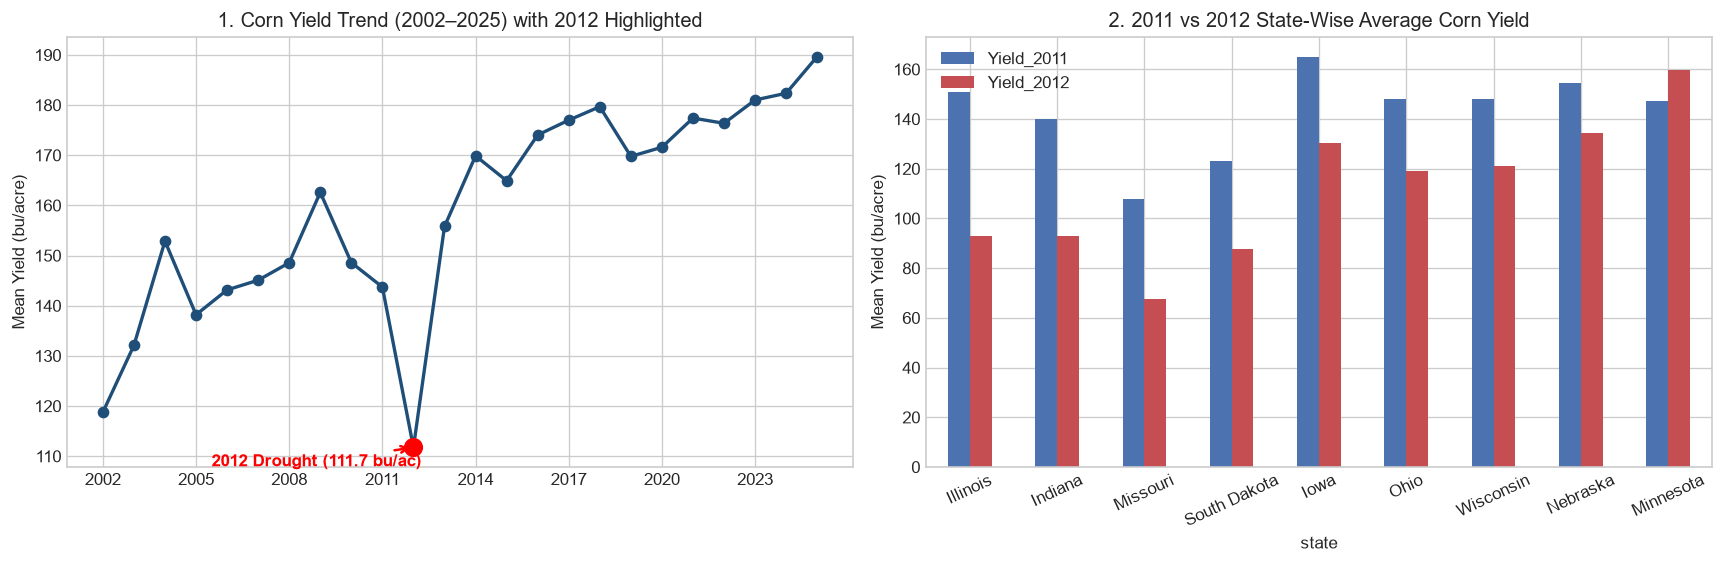

In [29]:
# Plot 1 & Plot 2: 2002-2025 trend with 2012 highlighted, and 2011 vs 2012 state-wise yield
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 4.8))

yr_avg = clean_df.groupby("year")["corn_yield_bu_acre"].mean().reset_index()
ax1.plot(yr_avg["year"], yr_avg["corn_yield_bu_acre"], marker="o", color="#1f4e78", lw=2)
d12_val = yr_avg.loc[yr_avg["year"] == 2012, "corn_yield_bu_acre"].values[0]
ax1.scatter([2012], [d12_val], color="red", s=110, zorder=5)
ax1.annotate(f"2012 Drought ({d12_val:.1f} bu/ac)", xy=(2012, d12_val), xytext=(2005.5, 108),
             arrowprops=dict(arrowstyle="->", color="red", lw=1.5), color="red", fontweight="bold")
ax1.set_title("1. Corn Yield Trend (2002–2025) with 2012 Highlighted")
ax1.set_ylabel("Mean Yield (bu/acre)")
ax1.set_xticks(range(2002, 2026, 3))

state_2012[["Yield_2011", "Yield_2012"]].plot(kind="bar", color=["#4c72b0", "#c44e52"], ax=ax2)
ax2.set_title("2. 2011 vs 2012 State-Wise Average Corn Yield")
ax2.set_ylabel("Mean Yield (bu/acre)")
ax2.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "drought_2012_trend_and_states.png", dpi=130)
plt.show()

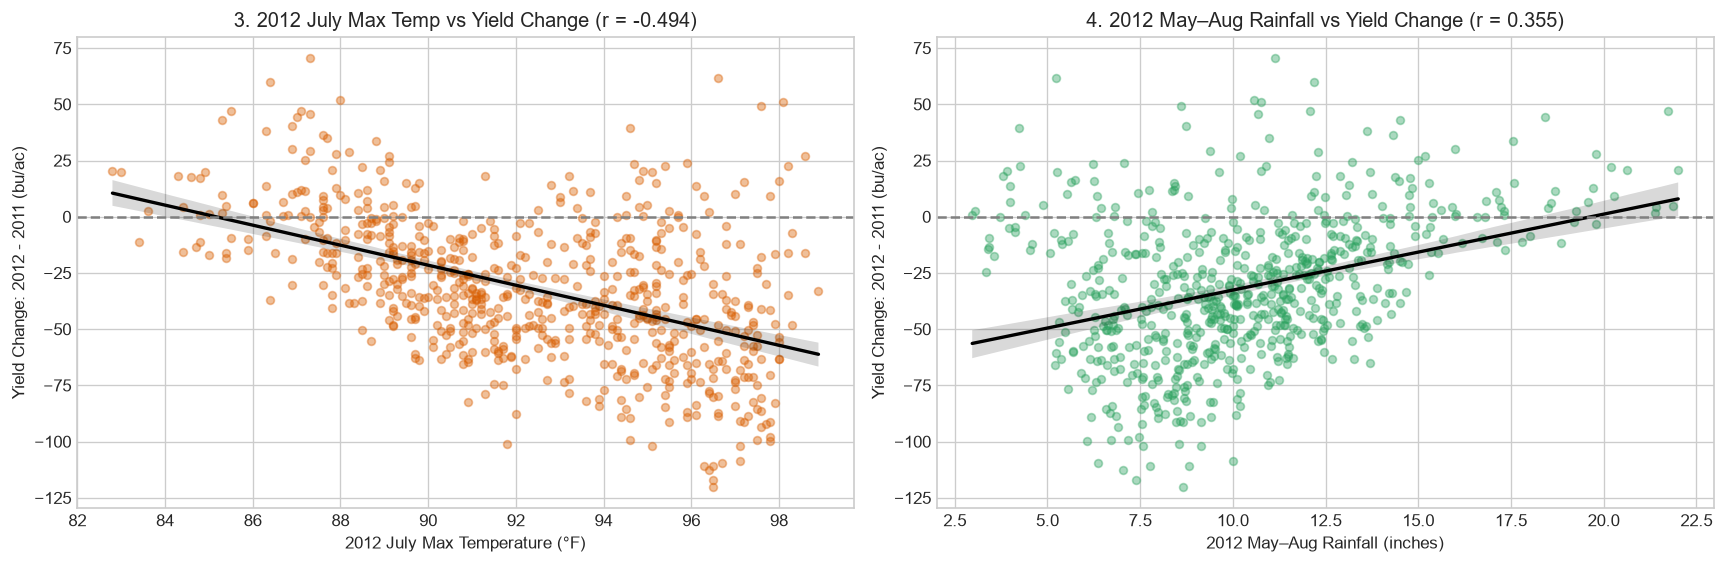

In [30]:
# Plot 3 & Plot 4: 2012 July temperature vs yield change, and 2012 rainfall vs yield change
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 4.8))

r_t_chg, _ = stats.pearsonr(comp_2012_full["noaa_tmax_jul_f"], comp_2012_full["yield_change"])
sns.regplot(data=comp_2012_full, x="noaa_tmax_jul_f", y="yield_change", ax=ax1,
            scatter_kws={"alpha": 0.4, "s": 22, "color": "#d95f02"}, line_kws={"color": "black", "lw": 2})
ax1.axhline(0, color="gray", linestyle="--")
ax1.set_title(f"3. 2012 July Max Temp vs Yield Change (r = {r_t_chg:.3f})")
ax1.set_xlabel("2012 July Max Temperature (°F)")
ax1.set_ylabel("Yield Change: 2012 - 2011 (bu/ac)")

r_p_chg, _ = stats.pearsonr(comp_2012_full["noaa_prcp_may_aug_in"], comp_2012_full["yield_change"])
sns.regplot(data=comp_2012_full, x="noaa_prcp_may_aug_in", y="yield_change", ax=ax2,
            scatter_kws={"alpha": 0.4, "s": 22, "color": "#2ca25f"}, line_kws={"color": "black", "lw": 2})
ax2.axhline(0, color="gray", linestyle="--")
ax2.set_title(f"4. 2012 May–Aug Rainfall vs Yield Change (r = {r_p_chg:.3f})")
ax2.set_xlabel("2012 May–Aug Rainfall (inches)")
ax2.set_ylabel("Yield Change: 2012 - 2011 (bu/ac)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "drought_2012_temp_rain_vs_loss.png", dpi=130)
plt.show()

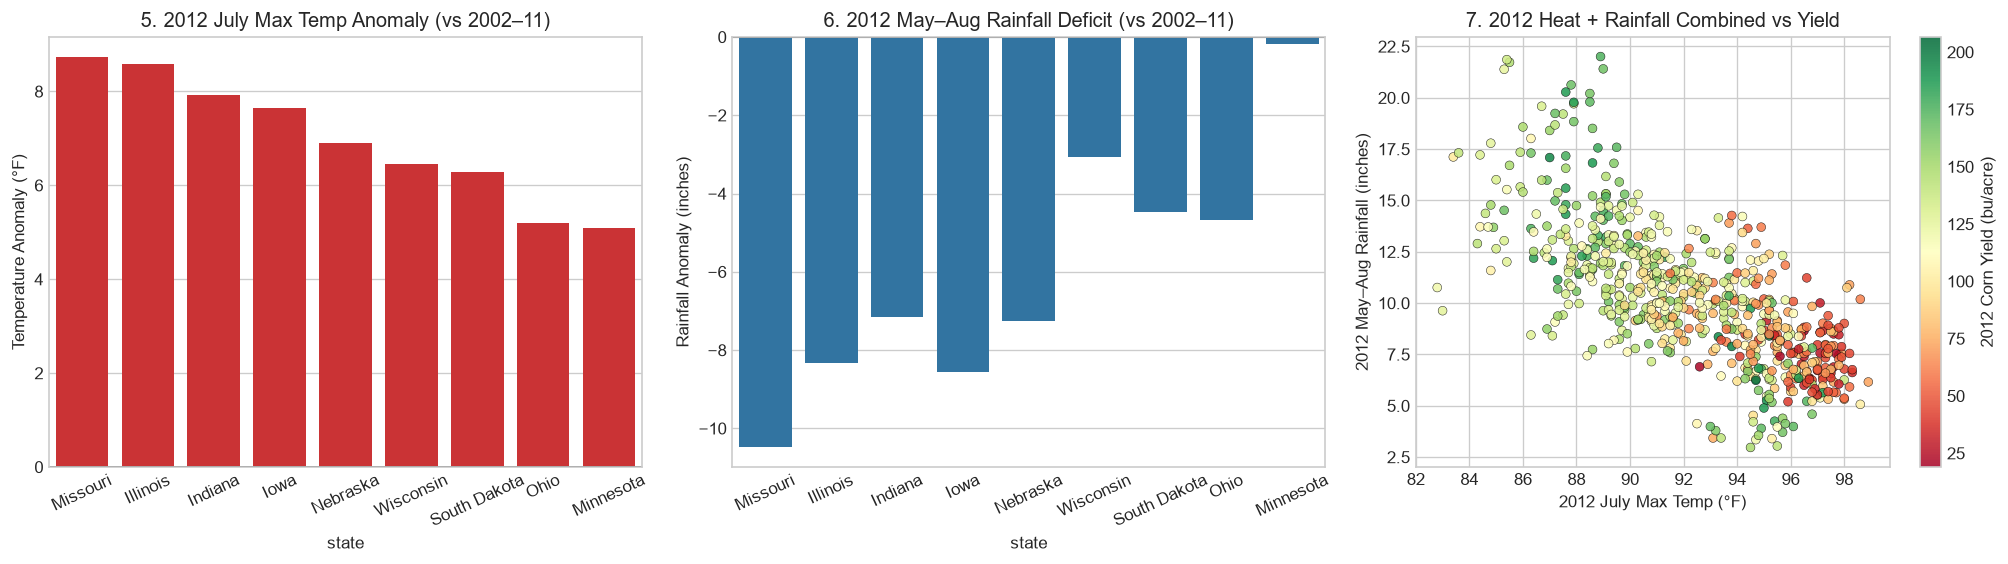

In [31]:
# Plot 5, Plot 6 & Plot 7: 2012 Temp Anomaly, 2012 Rainfall Deficit, and Combined Heat+Rain Impact
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

state_anom = comp_2012_full.groupby("state")[["jul_tmax_anom_f", "may_aug_prcp_anom_in"]].mean().sort_values("jul_tmax_anom_f", ascending=False)

sns.barplot(x=state_anom.index, y=state_anom["jul_tmax_anom_f"], color="#e31a1c", ax=axes[0])
axes[0].axhline(0, color="black", lw=1)
axes[0].set_title("5. 2012 July Max Temp Anomaly (vs 2002–11)")
axes[0].set_ylabel("Temperature Anomaly (°F)")
axes[0].tick_params(axis="x", rotation=25)

sns.barplot(x=state_anom.index, y=state_anom["may_aug_prcp_anom_in"], color="#1f78b4", ax=axes[1])
axes[1].axhline(0, color="black", lw=1)
axes[1].set_title("6. 2012 May–Aug Rainfall Deficit (vs 2002–11)")
axes[1].set_ylabel("Rainfall Anomaly (inches)")
axes[1].tick_params(axis="x", rotation=25)

sc = axes[2].scatter(
    comp_2012_full["noaa_tmax_jul_f"],
    comp_2012_full["noaa_prcp_may_aug_in"],
    c=comp_2012_full["yield_2012"],
    cmap="RdYlGn",
    s=28,
    alpha=0.85,
    edgecolor="black",
    linewidth=0.3,
)
cbar = plt.colorbar(sc, ax=axes[2])
cbar.set_label("2012 Corn Yield (bu/acre)")
axes[2].set_title("7. 2012 Heat + Rainfall Combined vs Yield")
axes[2].set_xlabel("2012 July Max Temp (°F)")
axes[2].set_ylabel("2012 May–Aug Rainfall (inches)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "drought_2012_anomalies_and_combined.png", dpi=130)
plt.show()

### 9.7 Historical Background & Interpretation of the 2012 Decline

- **Published National Context (USDA NASS 2013 Annual Summary, https://www.nass.usda.gov/Newsroom/archive/2013/01_11_2013.php):** Nationally across the entire United States, USDA reported average corn yield fell to **123.4 bushels per acre** in 2012 compared with **147.2 bushels per acre** in 2011, alongside a **13% decline** in total national corn production (`10.8 billion bushels`). *(These published national totals provide historical background and are kept separate from our nine-state county averages above.)*
- **Why July Heat and Dryness Matter Biologically:** July is the critical **silking and pollination** window for Midwest corn. When extreme daytime temperatures (`>90–95°F` in July) coincide with severe soil moisture deficits (below-normal June and July rainfall), pollen viability drops and kernel abortion increases.
- **What Our County Data Shows:** In our 9-state dataset, `2012` combined unusually warm June/July/August temperatures (with July maximum temperatures well above the `2002–2011` county baseline) and substantial May–August rainfall deficits. States in the central and southern Corn Belt (such as Missouri, Illinois, Indiana, and Iowa) suffered steep county-level yield drops, whereas counties with cooler temperatures, higher rainfall, or heavy irrigation (such as parts of Nebraska and northern Minnesota/Wisconsin) experienced smaller declines or even stable yields. Thus, the `2012` collapse reflects the **combined stress of heat, rainfall shortage, pollination timing, and local regional/irrigation factors**, rather than temperature acting alone.

## 10. Dependent and Independent Variables, 80:20 Split, and Statistical Analysis

### 10.1 Dependent Variable ($Y$) and Independent Variables ($X$)
- **Dependent Variable ($Y$):** `corn_yield_bu_acre` — the continuous corn grain yield we want to predict.
- **Independent Variables ($X$):** Growing-season NOAA temperature and rainfall, static `0–30 cm` SoilGrids features, pre-harvest USDA RMA insurance indicators, state crop condition and progress surveys, `year`, `state`, and strictly prior-year county yield (`yield_lag_1yr`, computed from `t - 1` within each county).

Let us construct `X` and `y` using historical observations (`2002–2025` only, verifying `2026` is absent) and create our **random 80:20 train-test split** (`random_state=42`).

In [32]:
model_df = clean_df[clean_df["year"] <= 2025].copy().sort_values(["county_fips", "year"]).reset_index(drop=True)

# Simple derived agro-climatic features and prior-year county yield lag (t-1)
model_df["prcp_jul_aug_in"] = model_df["noaa_prcp_jul_in"] + model_df["noaa_prcp_aug_in"]
model_df["diurnal_range_may_aug_f"] = model_df["noaa_tmax_may_aug_f"] - model_df["noaa_tmin_may_aug_f"]

lag_map = model_df.set_index(["county_fips", "year"])["corn_yield_bu_acre"]
model_df["yield_lag_1yr"] = [
    lag_map.get((fips, yr - 1), np.nan)
    for fips, yr in zip(model_df["county_fips"], model_df["year"])
]

numeric_features = [
    "year",
    "noaa_prcp_may_in", "noaa_prcp_jun_in", "noaa_prcp_jul_in", "noaa_prcp_aug_in", "noaa_prcp_sep_in",
    "noaa_prcp_may_aug_in", "noaa_prcp_may_sep_in", "prcp_jul_aug_in",
    "noaa_tmean_may_aug_f", "noaa_tmax_jul_f", "noaa_tmax_aug_f",
    "noaa_tmax_may_aug_f", "noaa_tmin_may_aug_f", "noaa_heat_stress_max_f", "diurnal_range_may_aug_f",
    "soil_intptlat", "soil_intptlon",
    "soil_clay_mean_0_30cm", "soil_sand_mean_0_30cm", "soil_silt_mean_0_30cm",
    "soil_soc_mean_0_30cm", "soil_ph_mean_0_30cm", "soil_bdod_mean_0_30cm",
    "rma_policies_sold", "rma_net_planted_acres", "rma_liability_per_planted_acre",
    "rma_premium_per_planted_acre", "rma_subsidy",
    "state_cond_good_excellent_mean", "state_cond_poor_very_poor_mean",
    "state_cond_rep_good_excellent_mean", "state_progress_planted_w20_pct",
    "state_progress_silking_w30_pct", "state_progress_dough_w34_pct",
    "yield_lag_1yr",
]
categorical_features = ["state"]
feature_columns = numeric_features + categorical_features

X = model_df[feature_columns].copy()
y = model_df["corn_yield_bu_acre"].copy()

print("Years in modeling dataset:", model_df["year"].min(), "to", model_df["year"].max(), "(2026 excluded:", (model_df["year"] == 2026).sum() == 0, ")")
print("Independent variables (X):", X.shape)
print("Dependent variable (y):", y.shape)
print("Feature list:", feature_columns)

Years in modeling dataset: 2002 to 2025 (2026 excluded: True )
Independent variables (X): (16390, 37)
Dependent variable (y): (16390,)
Feature list: ['year', 'noaa_prcp_may_in', 'noaa_prcp_jun_in', 'noaa_prcp_jul_in', 'noaa_prcp_aug_in', 'noaa_prcp_sep_in', 'noaa_prcp_may_aug_in', 'noaa_prcp_may_sep_in', 'prcp_jul_aug_in', 'noaa_tmean_may_aug_f', 'noaa_tmax_jul_f', 'noaa_tmax_aug_f', 'noaa_tmax_may_aug_f', 'noaa_tmin_may_aug_f', 'noaa_heat_stress_max_f', 'diurnal_range_may_aug_f', 'soil_intptlat', 'soil_intptlon', 'soil_clay_mean_0_30cm', 'soil_sand_mean_0_30cm', 'soil_silt_mean_0_30cm', 'soil_soc_mean_0_30cm', 'soil_ph_mean_0_30cm', 'soil_bdod_mean_0_30cm', 'rma_policies_sold', 'rma_net_planted_acres', 'rma_liability_per_planted_acre', 'rma_premium_per_planted_acre', 'rma_subsidy', 'state_cond_good_excellent_mean', 'state_cond_poor_very_poor_mean', 'state_cond_rep_good_excellent_mean', 'state_progress_planted_w20_pct', 'state_progress_silking_w30_pct', 'state_progress_dough_w34_pct', 

### 10.2 80:20 Train-Test Split
We split the `2002–2025` observations into 80% training (`X_train`, `y_train`) and 20% testing (`X_test`, `y_test`).  
**Important Limitation:** Because this is a **random 80:20 holdout split** across county-year panel rows (where the same years and counties appear in both training and test sets), it measures accuracy on randomly held-out county-years and does **not** independently prove future-year forecasting performance on unseen calendar years.

In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print(f"Total observations   : {len(X):,}")
print(f"Training observations: {len(X_train):,} ({len(X_train)/len(X)*100:.1f}%)")
print(f"Testing observations : {len(X_test):,} ({len(X_test)/len(X)*100:.1f}%)")
print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_test shape : {X_test.shape}  | y_test shape : {y_test.shape}")

Total observations   : 16,390
Training observations: 13,112 (80.0%)
Testing observations : 3,278 (20.0%)
X_train shape: (13112, 37) | y_train shape: (13112,)
X_test shape : (3278, 37)  | y_test shape : (3278,)


### 10.3 Statistical Analysis (Training Data Only)
To understand individual linear and monotonic relationships without touching the test set, we run:
- **Pearson ($r$) and Spearman ($\\rho$) correlations** on `X_train` and `y_train`.
- **Univariate F-Test (`f_regression`):** Computes an F-statistic and p-value for each numeric feature against `y_train`. Higher F-statistics and very small p-values (`< 0.05`) indicate stronger linear association—not causation.
- **Overall Regression F-Test (`statsmodels.OLS`):** Checks whether the combined linear model explains significantly more variance than an intercept-only mean model.

In [34]:
# Pearson & Spearman correlations on training set
stat_check_cols = [
    "yield_lag_1yr", "year", "state_cond_rep_good_excellent_mean",
    "noaa_tmax_jul_f", "noaa_tmean_may_aug_f", "noaa_prcp_may_aug_in",
    "prcp_jul_aug_in", "soil_soc_mean_0_30cm", "soil_ph_mean_0_30cm",
    "rma_liability_per_planted_acre"
]

corr_rows = []
for col in stat_check_cols:
    valid = X_train[col].notna()
    rp, pp = stats.pearsonr(X_train.loc[valid, col], y_train.loc[valid])
    rs, ps = stats.spearmanr(X_train.loc[valid, col], y_train.loc[valid])
    corr_rows.append({
        "Feature": col, "Pearson_r": round(rp, 4), "Pearson_p": f"{pp:.2e}",
        "Spearman_rho": round(rs, 4), "Spearman_p": f"{ps:.2e}",
    })
display(pd.DataFrame(corr_rows).sort_values("Pearson_r", key=lambda s: s.abs(), ascending=False))

# f_regression F-test on training data (using training median imputation only)
imp_stat = SimpleImputer(strategy="median")
X_tr_imp = imp_stat.fit_transform(X_train[numeric_features])
f_vals, p_vals = f_regression(X_tr_imp, y_train.values)

f_test_df = pd.DataFrame({
    "Feature": numeric_features,
    "F_statistic": np.round(f_vals, 2),
    "p_value": [f"{p:.2e}" for p in p_vals],
}).sort_values("F_statistic", ascending=False).reset_index(drop=True)

print("Top 15 Features by f_regression F-Statistic (Training Data Only):")
display(f_test_df.head(15))

# Overall OLS regression F-test on training data using linearly independent predictors (no exact sum collinearity)
ols_cols = [
    "year", "noaa_prcp_may_in", "noaa_prcp_jun_in", "noaa_prcp_jul_in", "noaa_prcp_aug_in",
    "noaa_tmean_may_aug_f", "noaa_tmax_jul_f", "soil_soc_mean_0_30cm", "soil_ph_mean_0_30cm",
    "soil_clay_mean_0_30cm", "rma_liability_per_planted_acre", "state_cond_rep_good_excellent_mean", "yield_lag_1yr"
]
ols_imp = SimpleImputer(strategy="median")
ols_tr = pd.DataFrame(ols_imp.fit_transform(X_train[ols_cols]), columns=ols_cols, index=X_train.index)
ols_model = sm.OLS(y_train, sm.add_constant(ols_tr)).fit()
print(f"Overall OLS Regression F-Test (Training Set): F = {ols_model.fvalue:.2f}, p-value = {ols_model.f_pvalue:.2e}, R² = {ols_model.rsquared:.4f}")

,Feature,Pearson_r,Pearson_p,Spearman_rho,Spearman_p
0,yield_lag_1yr,0.6746,0.00e+00,0.6936,0.00e+00
9,rma_liability_per_planted_acre,0.5544,0.00e+00,0.5766,0.00e+00
2,state_cond_rep_good_excellent_mean,0.4772,0.00e+00,0.4151,0.00e+00
1,year,0.4627,0.00e+00,0.4884,0.00e+00
3,noaa_tmax_jul_f,-0.3743,0.00e+00,-0.3037,8.13e-278
6,prcp_jul_aug_in,0.3177,3.31e-305,0.3151,4.35e-300
5,noaa_prcp_may_aug_in,0.2735,1.00e-223,0.2402,1.65e-171
7,soil_soc_mean_0_30cm,0.0444,3.62e-07,0.0545,4.24e-10
4,noaa_tmean_may_aug_f,-0.0406,3.27e-06,-0.0403,3.92e-06
8,soil_ph_mean_0_30cm,0.0190,2.94e-02,0.1044,4.54e-33


Top 15 Features by f_regression F-Statistic (Training Data Only):


,Feature,F_statistic,p_value
0,yield_lag_1yr,7468.93,0.00e+00
1,rma_liability_per_planted_acre,5457.79,0.00e+00
2,state_cond_poor_very_poor_mean,5038.17,0.00e+00
3,state_cond_rep_good_excellent_mean,3865.79,0.00e+00
4,state_cond_good_excellent_mean,3681.90,0.00e+00
5,year,3571.92,0.00e+00
6,rma_net_planted_acres,2603.53,0.00e+00
7,rma_policies_sold,2336.69,0.00e+00
8,noaa_heat_stress_max_f,2248.80,0.00e+00
9,diurnal_range_may_aug_f,2178.31,0.00e+00


Overall OLS Regression F-Test (Training Set): F = 2103.98, p-value = 0.00e+00, R² = 0.6762


## 11. Machine Learning Preprocessing and Model Training

### Preprocessing Pipeline (Fitted on Training Data Only)
Using `ColumnTransformer` and `Pipeline`, we:
1. Fill missing numeric values using the **training median** (`SimpleImputer`).
2. Scale numeric features using **training mean and standard deviation** (`StandardScaler`) for linear models (`LinearRegression`, `Ridge`, `Lasso`).
3. One-hot encode `state` (`OneHotEncoder`).

### Algorithms Used
1. **Linear Regression:** Fits a straight-line weighted sum of features.
2. **Ridge Regression:** Linear regression with $L_2$ penalty to stabilize correlated weather/soil weights.
3. **Lasso Regression:** Linear regression with $L_1$ penalty that can shrink weak weights to zero.
4. **Decision Tree Regressor:** Learns simple if/else split rules across features (depth-limited to reduce overfitting).
5. **Random Forest Regressor:** Averages many randomized decision trees to reduce prediction variance.
6. **Gradient Boosting Regressor:** Trains trees sequentially, where each new tree corrects errors from previous trees.
7. **XGBoost (when installed):** Fast regularized gradient-boosted trees for tabular data.

In [35]:
def make_preprocessor(scale_numeric=False):
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        num_steps.append(("scaler", StandardScaler()))
    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", Pipeline(num_steps), numeric_features),
        ("cat", cat_pipe, categorical_features),
    ])

model_specs = [
    ("Linear Regression", True, LinearRegression()),
    ("Ridge Regression", True, Ridge(alpha=10.0, random_state=RANDOM_STATE)),
    ("Lasso Regression", True, Lasso(alpha=0.1, max_iter=10000, random_state=RANDOM_STATE)),
    ("Decision Tree", False, DecisionTreeRegressor(max_depth=8, min_samples_leaf=15, random_state=RANDOM_STATE)),
    ("Random Forest", False, RandomForestRegressor(n_estimators=150, max_depth=14, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE)),
    ("Gradient Boosting", False, GradientBoostingRegressor(n_estimators=180, learning_rate=0.05, max_depth=4, random_state=RANDOM_STATE)),
]

if xgb is not None:
    model_specs.append((
        "XGBoost", False,
        xgb.XGBRegressor(n_estimators=250, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1, verbosity=0)
    ))

results_list = []
trained_models = {}
test_predictions = {}

for name, use_scaler, estimator in model_specs:
    pipe = Pipeline([
        ("prep", make_preprocessor(scale_numeric=use_scaler)),
        ("model", estimator),
    ])
    t0 = time.perf_counter()
    pipe.fit(X_train, y_train)
    train_sec = time.perf_counter() - t0

    pred_tr = pipe.predict(X_train)
    pred_te = pipe.predict(X_test)
    trained_models[name] = pipe
    test_predictions[name] = pred_te

    mse_te = mean_squared_error(y_test, pred_te)
    results_list.append({
        "Model": name,
        "Train_R2": round(r2_score(y_train, pred_tr), 4),
        "R2_Score": round(r2_score(y_test, pred_te), 4),
        "MAE": round(mean_absolute_error(y_test, pred_te), 2),
        "MSE": round(mse_te, 2),
        "RMSE": round(np.sqrt(mse_te), 2),
        "Train_Time_s": round(train_sec, 2),
    })

results_df = pd.DataFrame(results_list).sort_values("RMSE", ascending=True).reset_index(drop=True)
results_df.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
display(results_df)

,Model,Train_R2,R2_Score,MAE,MSE,RMSE,Train_Time_s
0,XGBoost,0.9439,0.8801,9.29,149.24,12.22,0.58
1,Random Forest,0.9386,0.8539,10.17,181.88,13.49,2.79
2,Gradient Boosting,0.8758,0.8379,10.89,201.74,14.20,14.31
3,Decision Tree,0.7859,0.7389,13.85,324.92,18.03,0.19
4,Ridge Regression,0.7534,0.7364,13.73,328.06,18.11,0.04
5,Linear Regression,0.7534,0.7362,13.74,328.37,18.12,0.05
6,Lasso Regression,0.7507,0.7362,13.73,328.27,18.12,0.51


## 12. Model Evaluation

- **R² Score:** Share of yield variance explained (`1.0` is perfect).
- **MAE (Mean Absolute Error):** Average absolute prediction error in `bu/acre`.
- **MSE & RMSE:** Squared error and its square root in `bu/acre` (penalizes large errors more strongly than MAE).

Below we plot Actual vs. Predicted yields, residuals, model-wise RMSE, error distribution, and yearly average actual vs. predicted yield comparison on the 20% test set.

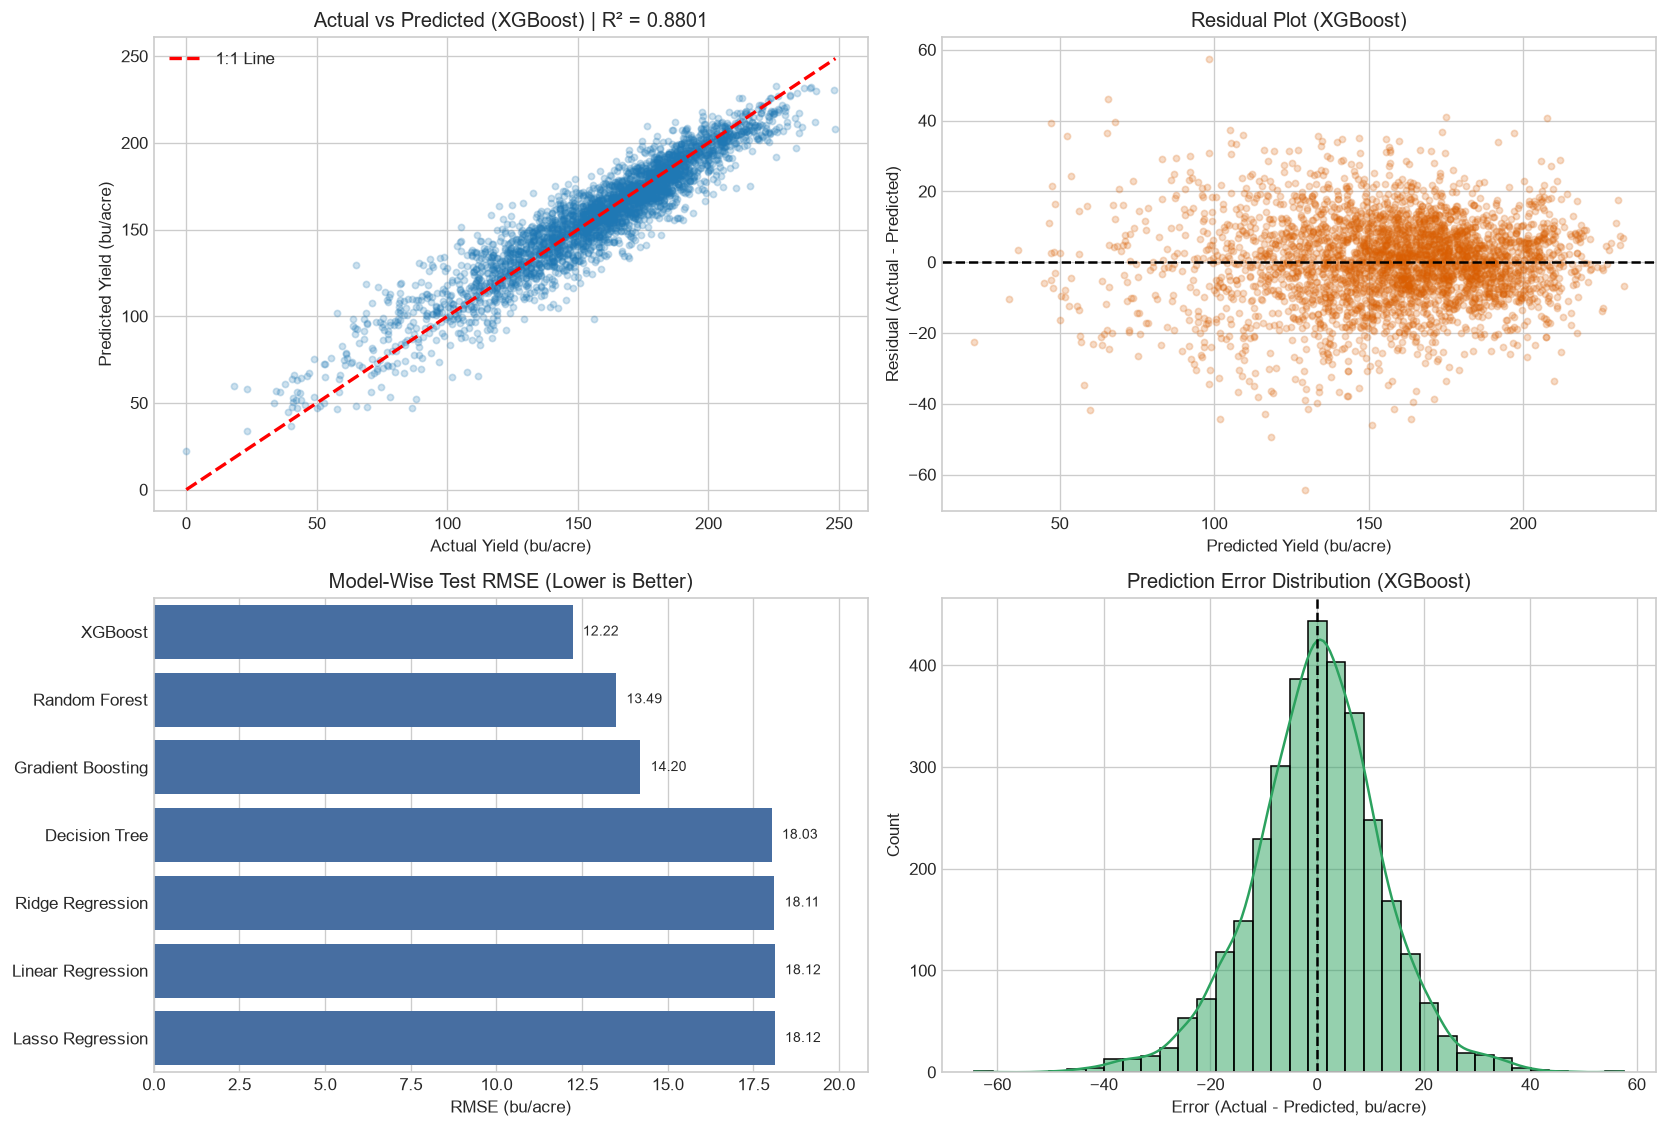

In [36]:
best_model_name = results_df.iloc[0]["Model"]
y_pred_best = test_predictions[best_model_name]
residuals = y_test.values - y_pred_best

fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))

# 1. Actual vs Predicted
axes[0, 0].scatter(y_test, y_pred_best, alpha=0.22, s=14, color="#1f78b4")
lims = [min(y_test.min(), y_pred_best.min()), max(y_test.max(), y_pred_best.max())]
axes[0, 0].plot(lims, lims, "r--", lw=2, label="1:1 Line")
axes[0, 0].set_title(f"Actual vs Predicted ({best_model_name}) | R² = {results_df.iloc[0]['R2_Score']:.4f}")
axes[0, 0].set_xlabel("Actual Yield (bu/acre)")
axes[0, 0].set_ylabel("Predicted Yield (bu/acre)")
axes[0, 0].legend()

# 2. Residual Plot
axes[0, 1].scatter(y_pred_best, residuals, alpha=0.22, s=14, color="#d95f02")
axes[0, 1].axhline(0, color="black", linestyle="--")
axes[0, 1].set_title(f"Residual Plot ({best_model_name})")
axes[0, 1].set_xlabel("Predicted Yield (bu/acre)")
axes[0, 1].set_ylabel("Residual (Actual - Predicted)")

# 3. Model-wise RMSE
sns.barplot(data=results_df, y="Model", x="RMSE", color="#386cb0", ax=axes[1, 0])
axes[1, 0].set_title("Model-Wise Test RMSE (Lower is Better)")
axes[1, 0].set_xlabel("RMSE (bu/acre)")
axes[1, 0].set_ylabel("")
for bar, (_, r) in zip(axes[1, 0].patches, results_df.iterrows()):
    axes[1, 0].text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2, f"{r['RMSE']:.2f}", va="center", fontsize=8.5)
axes[1, 0].set_xlim(0, results_df["RMSE"].max() * 1.15)

# 4. Error Distribution
sns.histplot(residuals, bins=35, kde=True, color="#2ca25f", ax=axes[1, 1])
axes[1, 1].axvline(0, color="black", linestyle="--")
axes[1, 1].set_title(f"Prediction Error Distribution ({best_model_name})")
axes[1, 1].set_xlabel("Error (Actual - Predicted, bu/acre)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "model_evaluation_diagnostics.png", dpi=130)
plt.show()

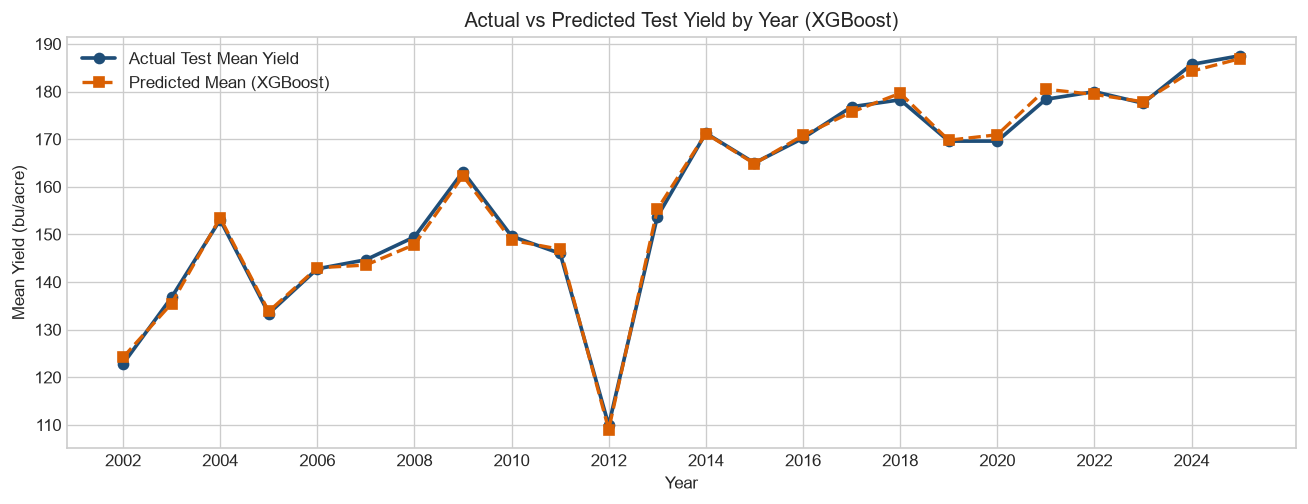

In [37]:
# 5. Actual vs Predicted Annual Mean Comparison on Test Set
test_yr_comp = pd.DataFrame({
    "year": X_test["year"].values,
    "Actual": y_test.values,
    "Predicted": y_pred_best,
}).groupby("year")[["Actual", "Predicted"]].mean().reset_index()

fig, ax = plt.subplots(figsize=(11, 4.3))
ax.plot(test_yr_comp["year"], test_yr_comp["Actual"], marker="o", lw=2.2, label="Actual Test Mean Yield", color="#1f4e78")
ax.plot(test_yr_comp["year"], test_yr_comp["Predicted"], marker="s", linestyle="--", lw=2, label=f"Predicted Mean ({best_model_name})", color="#d95f02")
ax.set_title(f"Actual vs Predicted Test Yield by Year ({best_model_name})")
ax.set_ylabel("Mean Yield (bu/acre)")
ax.set_xlabel("Year")
ax.set_xticks(range(2002, 2026, 2))
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "actual_vs_predicted_by_year.png", dpi=130)
plt.show()

## 13. Supplementary Classification Demonstration (Confusion Matrix & F1-Score)

Because maize yield (`corn_yield_bu_acre`) is continuous, our main project is a **regression** problem. As an extra classification exercise, we convert yield into three categories (`Low Yield`, `Medium Yield`, `High Yield`) using **training-set (`y_train`) quantiles only**, train a separate `RandomForestClassifier`, and display its confusion matrix and F1-scores.

- **False Positive (for a category like `High Yield`):** Predicting a county-year is `High Yield` when its actual yield was `Medium` or `Low`.
- **False Negative (for `High Yield`):** Predicting `Medium` or `Low` when the county-year actually achieved `High Yield`.

Training-Only Thresholds: Low <= 147.00 | Medium (147.00–175.60] | High > 175.60 bu/ac
Macro F1 = 0.7958 | Weighted F1 = 0.7961

              precision    recall  f1-score   support

   Low Yield     0.8632    0.8294    0.8460      1096
Medium Yield     0.6762    0.7380    0.7058      1084
  High Yield     0.8580    0.8142    0.8355      1098

    accuracy                         0.7941      3278
   macro avg     0.7992    0.7939    0.7958      3278
weighted avg     0.7996    0.7941    0.7961      3278



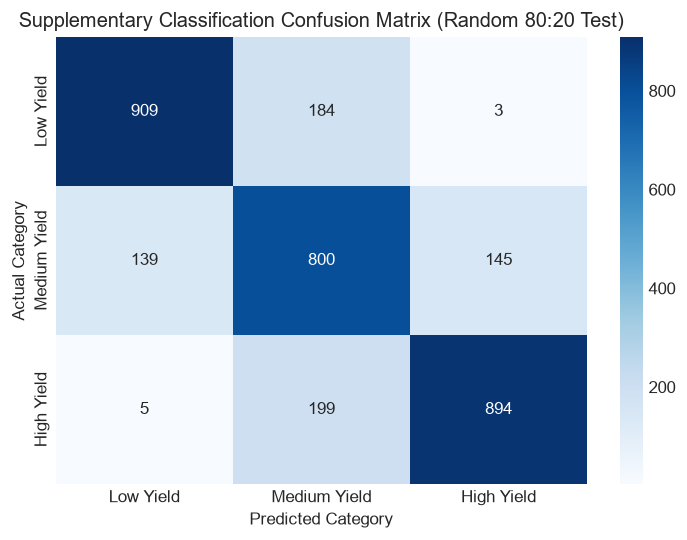

In [38]:
# Define thresholds using training yields ONLY
q33, q67 = np.quantile(y_train, [1 / 3, 2 / 3])
cls_labels = ["Low Yield", "Medium Yield", "High Yield"]

def to_yield_class(arr):
    return np.where(arr <= q33, "Low Yield", np.where(arr <= q67, "Medium Yield", "High Yield"))

y_train_cls = to_yield_class(y_train.values)
y_test_cls = to_yield_class(y_test.values)

clf = Pipeline([
    ("prep", make_preprocessor(scale_numeric=False)),
    ("clf", RandomForestClassifier(n_estimators=150, max_depth=14, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE)),
])
clf.fit(X_train, y_train_cls)
y_pred_cls = clf.predict(X_test)

cm = confusion_matrix(y_test_cls, y_pred_cls, labels=cls_labels)
macro_f1 = f1_score(y_test_cls, y_pred_cls, average="macro")
weighted_f1 = f1_score(y_test_cls, y_pred_cls, average="weighted")

print(f"Training-Only Thresholds: Low <= {q33:.2f} | Medium ({q33:.2f}–{q67:.2f}] | High > {q67:.2f} bu/ac")
print(f"Macro F1 = {macro_f1:.4f} | Weighted F1 = {weighted_f1:.4f}\n")
print(classification_report(y_test_cls, y_pred_cls, labels=cls_labels, digits=4))

fig, ax = plt.subplots(figsize=(6.2, 4.6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=cls_labels, yticklabels=cls_labels, ax=ax)
ax.set_title("Supplementary Classification Confusion Matrix (Random 80:20 Test)")
ax.set_xlabel("Predicted Category")
ax.set_ylabel("Actual Category")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "supplementary_confusion_matrix.png", dpi=130)
plt.show()

## 14. Final Conclusion

The code below prints a concise summary computed directly from the executed pipeline outputs so every reported number matches this notebook run.

In [39]:
best_row = results_df.iloc[0]
print("=== EXECUTED PROJECT SUMMARY ===")
print(f"1. Datasets Loaded    : 8 cleaned domain tables + raw USDA NASS & NOAA files from GitHub")
print(f"2. Integrated Dataset : {clean_df.shape[0]:,} county-years across {clean_df['county_fips'].nunique()} counties (2002–2025)")
print(f"3. 2012 Drought Check : Consistent counties (N={int(tbl_11_13.loc[tbl_11_13['year']==2012, 'Number_of_Counties'].values[0])}) changed {pct_11_12:+.2f}% from 2011 to 2012 and {pct_12_13:+.2f}% in 2013")
print(f"4. 80:20 Split        : Train = {len(X_train):,} rows (80%) | Test = {len(X_test):,} rows (20%)")
print(f"5. Best Regressor     : {best_row['Model']} | Test R² = {best_row['R2_Score']:.4f}, MAE = {best_row['MAE']:.2f}, RMSE = {best_row['RMSE']:.2f} bu/acre")
print(f"6. Extra Classifier   : RandomForestClassifier Macro F1 = {macro_f1:.4f}, Weighted F1 = {weighted_f1:.4f}")

=== EXECUTED PROJECT SUMMARY ===
1. Datasets Loaded    : 8 cleaned domain tables + raw USDA NASS & NOAA files from GitHub
2. Integrated Dataset : 16,390 county-years across 788 counties (2002–2025)
3. 2012 Drought Check : Consistent counties (N=629) changed -21.47% from 2011 to 2012 and +36.73% in 2013
4. 80:20 Split        : Train = 13,112 rows (80%) | Test = 3,278 rows (20%)
5. Best Regressor     : XGBoost | Test R² = 0.8801, MAE = 9.29, RMSE = 12.22 bu/acre
6. Extra Classifier   : RandomForestClassifier Macro F1 = 0.7958, Weighted F1 = 0.7961


**Key Takeaways:**
- Multi-source joining on `county_fips` and `year` (with `many_to_one` joins for static SoilGrids and state-level surveys) preserves exact county-year counts without duplicate inflation.
- In `2012`, unusually hot June–August temperatures combined with strong May–August rainfall deficits led to severe yield declines across most of the Corn Belt, followed by recovery in `2013`.
- Tree-based and gradient-boosted regression models outperform simple linear baselines on the random 80:20 holdout split (`2002–2025`), while keeping in mind that a random split across repeated county-year rows does not replace strict out-of-time forecasting for future unseen years.